# Trực quan hóa dữ liệu KLTN — theo đúng bảng phân chia trong Google Docs

Notebook này **chỉ vẽ dữ liệu**: không so sánh, không xếp hạng, không nhận xét. Mỗi mục dưới đây
là một dòng trong bảng của tài liệu, vẽ đúng phạm vi và **đủ số ngân hàng** đã ghi ở đó.

| # | Khối dữ liệu | Khoảng | Số NH | Bảng đọc |
|---|---|---|---|---|
| 1 | Giá cổ phiếu | 2015-09 → 2026-09 | 22 | `fact_price_daily` |
| 2 | BCTC (BS/IS/CF/ratio) | 2018-Q1 → 2026-Q2 | 22 | `fact_financial` |
| 3 | Tín dụng theo ngân hàng | 2018-Q1 → 2026-Q2 | 22 | `fact_bank_quarterly` |
| 4 | Chi phí vốn (COF) | 2018-Q1 → 2026-Q2 | 22 | `bank_cost_of_funds_quarterly` |
| 5 | Lợi suất tài sản sinh lời | 2018-Q1 → 2026-Q2 | 22 | `bank_earning_asset_yield_quarterly` |
| 6 | CPI | 2017-07 → 2026-07 | – | `fact_macro_monthly` |
| 7 | Tăng trưởng tín dụng hệ thống | 2018 → 2025 | – | `fact_credit_growth_yearly` |
| 8 | Lãi suất điều hành SBV | 2017-07 → 2023-06 | – | `fact_policy_rate_event` |
| 9 | Bình quân ngành (SBV) | 2024-01 → 2026-07 | – | `loan_industry_avg` |
| 10 | Lãi suất cho vay theo NH | 2025-01 → 2026-07 | 22 | `fact_lending_rate_monthly` |
| 11 | Lãi suất tiết kiệm niêm yết | 2026-08-21 → 09-03 | 17 | `fact_deposit_rate` |
| 12 | Harvard Dataverse | 2002 → 2022 | 45 | `vn_banking_system_2002_2021_data` |
| 13 | Mạng lưới | ảnh chụp hiện tại | 22 | `fact_branch_point`, `fact_branch_by_province` |
| 14 | Đánh giá app | 2012-01 → 2026-08 | 22 | `fact_app_review_monthly` |

**22 mã niêm yết ghi trong tài liệu:** ACB, BAB, BID, BVB, CTG, EIB, HDB, LPB, MBB, MSB, NAB,
NVB, OCB, PGB, SHB, SSB, STB, TCB, TPB, VCB, VIB, VPB — ô nạp dữ liệu bên dưới đối chiếu danh
sách này với `dim_bank.is_listed` và dừng ngay nếu lệch.

Ba cách vẽ được lặp lại cho dễ đọc: **lưới nhỏ** (mỗi ngân hàng một ô — nhìn hết 22 hoặc 45 mã mà
không rối), **thanh ngang** (xếp theo giá trị, nhãn số ngay đầu thanh), và **bản đồ nhiệt**
(ngân hàng × thời gian, hoặc ngân hàng × kỳ hạn).

In [1]:
from __future__ import annotations

import os
import sys
import textwrap
import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, Normalize

warnings.filterwarnings("ignore", category=FutureWarning)
TREN_COLAB = "google.colab" in sys.modules


def _co_du_lieu(d):
    return (d / "data" / "powerbi" / "dim_bank.csv").is_file()


def tim_goc():
    # Tìm gốc dự án: biến môi trường -> đi ngược lên từ thư mục hiện tại -> /content, Drive (Colab)
    if os.environ.get("KLTN_ROOT"):
        return Path(os.environ["KLTN_ROOT"])
    here = Path.cwd().resolve()
    for d in [here, *here.parents]:
        if _co_du_lieu(d):
            return d
    if TREN_COLAB:
        for goc in (Path("/content"), Path("/content/drive/MyDrive")):
            if not goc.is_dir():
                continue
            for muc in range(0, 4):
                for d in ([goc] if muc == 0 else goc.glob("/".join(["*"] * muc))):
                    if d.is_dir() and _co_du_lieu(d):
                        return d
    raise FileNotFoundError(
        "Khong tim thay data/powerbi/dim_bank.csv.\n"
        "  - May ca nhan: mo notebook tu trong thu muc du an, hoac dat ROOT = Path(r'D:/KLTN')\n"
        "  - Colab: nen bang  python nen_powerbi.py  roi tai powerbi.zip len, giai vao /content/KLTN/data/"
    )


ROOT = tim_goc()
PBI = ROOT / "data" / "powerbi"
LSD = ROOT / "data" / "interest_rates"      # COF + lợi suất tài sản sinh lời (mục 4, 5)
NGOAI = ROOT / "data" / "external"          # Harvard Dataverse (mục 12)
FIGDIR = ROOT / "figures_doc"
SAVE_FIG = True
if SAVE_FIG:
    FIGDIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)

print("Gốc dự án:", ROOT)
print("Có mặt   :", len(sorted(PBI.glob("*.csv"))), "file CSV trong data/powerbi")
for ten, p in [("chi phí vốn", LSD / "bank_cost_of_funds_quarterly.csv"),
               ("lợi suất TSSL", LSD / "bank_earning_asset_yield_quarterly.csv"),
               ("Harvard Dataverse", NGOAI / "vn_banking_system_2002_2021_data.csv"),
               ("bình quân ngành", ROOT / "data" / "loan_rates" / "loan_industry_avg.csv")]:
    print(f"  {ten:18s}", "có" if p.is_file() else "THIẾU — mục tương ứng sẽ tự bỏ qua")

Gốc dự án: D:\KLTN
Có mặt   : 17 file CSV trong data/powerbi
  chi phí vốn        có
  lợi suất TSSL      có
  Harvard Dataverse  có
  bình quân ngành    có


## 0. Bảng màu, khung hình và các hàm vẽ dùng chung

Bốn hàm gánh gần hết notebook: `luoi_nho` (mỗi ngân hàng một ô), `thanh_ngang` (xếp theo giá trị,
có nhãn số), `ban_do_nhiet` (ngân hàng × thời gian / kỳ hạn) và `khung` (tiêu đề hai tầng + ghi
chú nguồn ở chân hình). Nhờ dùng chung, 14 mục có cùng một ngôn ngữ hình ảnh.

In [2]:
SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK_2 = "#52514e"
INK_3 = "#7b7a75"
GRID = "#e8e7e3"
AXIS = "#d8d7d2"
MUTED = "#c9c8c3"

XANH = "#2a78d6"
CAM = "#eb6834"
NGOC = "#1baf7a"
VANG = "#eda100"
TIM = "#4a3aa7"
DO = "#e34948"

SEQ = LinearSegmentedColormap.from_list(
    "seq_blue",
    ["#eaf2fd", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
SEQ_CAM = LinearSegmentedColormap.from_list(
    "seq_orange",
    ["#fdf1ea", "#fbd9c4", "#f7b795", "#f09266", "#e5713f", "#c9541f", "#9c3d12"])

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "figure.dpi": 110,
    "savefig.dpi": 190, "savefig.facecolor": SURFACE, "savefig.bbox": "tight",
    "axes.facecolor": SURFACE, "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "xtick.color": INK_2, "ytick.color": INK_2, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "text.color": INK, "font.family": "sans-serif",
    "font.sans-serif": ["Segoe UI", "Tahoma", "DejaVu Sans", "Arial"], "font.size": 10,
    "legend.frameon": False, "legend.fontsize": 9,
})


def luu(fig, ten):
    if SAVE_FIG:
        fig.savefig(FIGDIR / (ten + ".png"))
        print("đã lưu →", ten + ".png")


def dau_de(fig, phu=True):
    # Mép trên của vùng vẽ, chừa đúng chỗ cho khối tiêu đề — tính bằng inch nên
    # hình cao hay thấp đều không bị chữ đè lên biểu đồ.
    return 1 - (0.80 if phu else 0.48) / fig.get_figheight()


def khung(fig, tieu_de, phu=None, nguon=None):
    # Tiêu đề hai tầng ở mức figure: dùng chung cho hình đơn lẫn lưới nhiều ô.
    h = fig.get_figheight()
    fig.text(0.008, 1 - 0.10 / h, tieu_de, fontsize=14.5, fontweight="600", color=INK,
             ha="left", va="top")
    if phu:
        fig.text(0.008, 1 - 0.44 / h, phu, fontsize=10.2, color=INK_2, ha="left", va="top")
    if nguon:
        fig.text(0.008, -0.10 / h, textwrap.fill(nguon, 145), fontsize=8.4, color=INK_3,
                 ha="left", va="top")


def luoi_nho(n, ncot=6, cao=1.45, rong=2.15, **kw):
    # "Small multiples": mỗi ngân hàng một ô. Ô thừa được ẩn đi.
    nhang = int(np.ceil(n / ncot))
    fig, axes = plt.subplots(nhang, ncot, figsize=(ncot * rong, nhang * cao), **kw)
    axes = np.atleast_1d(axes).ravel()
    for ax in axes[n:]:
        ax.set_visible(False)
    for ax in axes[:n]:
        ax.tick_params(labelsize=7.5, length=2)
    return fig, axes[:n]


def ten_o(ax, ten, mau=INK, phu=None):
    ax.set_title(ten, fontsize=9.5, fontweight="600", color=mau, pad=3, loc="left")
    if phu:
        ax.text(1.0, 1.02, phu, transform=ax.transAxes, ha="right", va="bottom",
                fontsize=7.6, color=INK_3)


def thanh_ngang(ax, nhan, gia_tri, mau=XANH, dinh_dang="{:,.0f}", don_vi="", cao=0.74):
    # Thanh ngang có nhãn số ngay sau đầu thanh — người đọc không phải dò trục.
    gia_tri = np.asarray(gia_tri, dtype=float)
    y = np.arange(len(nhan))
    mau_list = mau if isinstance(mau, (list, np.ndarray)) else [mau] * len(nhan)
    ax.barh(y, gia_tri, height=cao, color=mau_list, zorder=3)
    ax.set_yticks(y)
    ax.set_yticklabels(nhan, fontsize=9)
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
    lon = np.nanmax(gia_tri) if len(gia_tri) else 1
    ax.set_xlim(0, lon * 1.16)
    for yi, v in zip(y, gia_tri):
        if np.isnan(v):
            continue
        ax.text(v + lon * 0.014, yi, dinh_dang.format(v) + don_vi, va="center", ha="left",
                fontsize=8.6, color=INK_2)
    return ax


def ban_do_nhiet(ax, M, cmap=SEQ, dinh_dang="{:.1f}", chu=True, vmin=None, vmax=None,
                 co_chu=7.6, moi_nhan_x=1, xoay=90):
    # M: hàng = ngân hàng, cột = mốc thời gian hoặc kỳ hạn. Ô trắng = không có số liệu.
    A = M.to_numpy(dtype=float)
    im = ax.imshow(A, cmap=cmap, aspect="auto",
                   vmin=np.nanmin(A) if vmin is None else vmin,
                   vmax=np.nanmax(A) if vmax is None else vmax)
    vt = list(range(0, M.shape[1], moi_nhan_x))
    ax.set_xticks(vt)
    ax.set_xticklabels([str(M.columns[i]) for i in vt], fontsize=8, rotation=xoay)
    ax.set_yticks(range(M.shape[0]))
    ax.set_yticklabels(M.index, fontsize=8.8)
    ax.grid(False)
    ax.set_xticks(np.arange(-0.5, M.shape[1], 1), minor=True)
    ax.set_yticks(np.arange(-0.5, M.shape[0], 1), minor=True)
    ax.tick_params(which="minor", length=0)
    ax.grid(which="minor", color=SURFACE, linewidth=1.1)
    if chu:
        chuan = Normalize(*im.get_clim())
        for i in range(M.shape[0]):
            for j in range(M.shape[1]):
                v = A[i, j]
                if np.isnan(v):
                    continue
                ax.text(j, i, dinh_dang.format(v), ha="center", va="center", fontsize=co_chu,
                        color="white" if chuan(v) > 0.62 else INK)
    return im


def nghin_ty(x):
    return np.asarray(x, dtype=float) / 1e12        # VNĐ -> nghìn tỷ đồng


print("Đã nạp bảng màu và các hàm vẽ dùng chung.")

Đã nạp bảng màu và các hàm vẽ dùng chung.


### Nạp dữ liệu một lần

Các mục sau chỉ lấy ra dùng, không đọc lại đĩa. `NH22` là 22 mã trong tài liệu, `TEN` là bản đồ
mã → tên ngân hàng để dán nhãn.

In [3]:
def doc(ten, **kw):
    return pd.read_csv(PBI / (ten + ".csv"), encoding="utf-8-sig", low_memory=False, **kw)


dim_bank = doc("dim_bank")
niem_yet = dim_bank[dim_bank["is_listed"] == True].copy()          # noqa: E712
NH22 = sorted(niem_yet["ticker"].tolist())
KEY = dict(zip(niem_yet["ticker"], niem_yet["bank_key"]))
MA = {v: k for k, v in KEY.items()}
TEN = dict(zip(niem_yet["ticker"], niem_yet["bank_name"]))

DOC22 = ("ACB BAB BID BVB CTG EIB HDB LPB MBB MSB NAB "
         "NVB OCB PGB SHB SSB STB TCB TPB VCB VIB VPB").split()
assert NH22 == sorted(DOC22), "Danh sách mã khác với tài liệu: " + str(set(NH22) ^ set(DOC22))

gia = doc("fact_price_daily", parse_dates=["date"])
tai_chinh = doc("fact_financial")
quy = doc("fact_bank_quarterly", parse_dates=["period_end"])
vi_mo = doc("fact_macro_monthly", parse_dates=["month_date"])
tin_dung_nam = doc("fact_credit_growth_yearly")
dieu_hanh = doc("fact_policy_rate_event", parse_dates=["date_effective"])
cho_vay = doc("fact_lending_rate_monthly", parse_dates=["month_date"])
tiet_kiem = doc("fact_deposit_rate", parse_dates=["date"])
diem_ml = doc("fact_branch_point")
tinh_ml = doc("fact_branch_by_province")
app_thang = doc("fact_app_review_monthly", parse_dates=["month_date"])
metric = doc("dim_metric")

CO_COF = (LSD / "bank_cost_of_funds_quarterly.csv").is_file()
CO_TSSL = (LSD / "bank_earning_asset_yield_quarterly.csv").is_file()
CO_DV = (NGOAI / "vn_banking_system_2002_2021_data.csv").is_file()
CO_NGANH = (ROOT / "data" / "loan_rates" / "loan_industry_avg.csv").is_file()

cof = pd.read_csv(LSD / "bank_cost_of_funds_quarterly.csv", encoding="utf-8-sig") if CO_COF else None
tssl = pd.read_csv(LSD / "bank_earning_asset_yield_quarterly.csv", encoding="utf-8-sig") if CO_TSSL else None
nganh = (pd.read_csv(ROOT / "data" / "loan_rates" / "loan_industry_avg.csv",
                     encoding="utf-8-sig", parse_dates=["date"]) if CO_NGANH else None)

print(len(NH22), "mã niêm yết:", " ".join(NH22))
print(f"giá {len(gia):,} phiên · BCTC {len(tai_chinh):,} dòng · tín dụng {len(quy):,} dòng · "
      f"tiết kiệm {len(tiet_kiem):,} dòng · cho vay {len(cho_vay):,} dòng · app {len(app_thang):,} dòng")

22 mã niêm yết: ACB BAB BID BVB CTG EIB HDB LPB MBB MSB NAB NVB OCB PGB SHB SSB STB TCB TPB VCB VIB VPB
giá 47,206 phiên · BCTC 35,556 dòng · tín dụng 748 dòng · tiết kiệm 17,719 dòng · cho vay 375 dòng · app 2,093 dòng


## 1. Giá cổ phiếu — 22 ngân hàng, 2015-09 → 2026-09

Mỗi ô là một mã, trục thời gian dùng chung nên nhìn ngang là thấy cùng một giai đoạn. Trục giá để
riêng từng ô vì giá tuyệt đối giữa các mã không cùng thang — con số ở góc phải mỗi ô là giá đóng
cửa phiên gần nhất.

đã lưu → doc_01a_gia_dong_cua_22nh.png


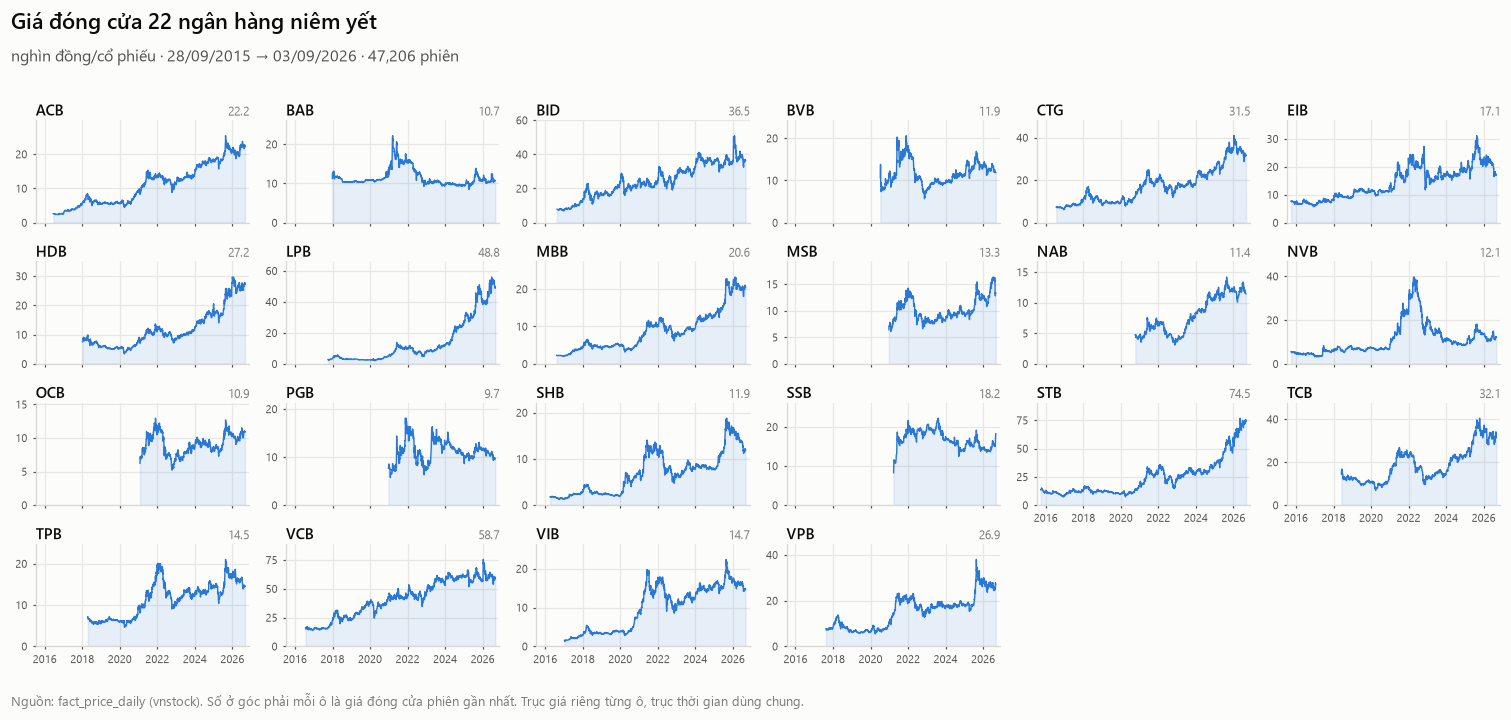

In [4]:
gia22 = gia[gia["ticker"].isin(NH22)].sort_values("date")

fig, axes = luoi_nho(22, ncot=6, cao=1.55, rong=2.3, sharex=True)
for ax, ma in zip(axes, NH22):
    d = gia22[gia22["ticker"] == ma]
    ax.plot(d["date"], d["close"], lw=0.9, color=XANH)
    ax.fill_between(d["date"], d["close"], color=XANH, alpha=0.10)
    ax.set_ylim(0, d["close"].max() * 1.18)
    ten_o(ax, ma, phu=f"{d['close'].iloc[-1]:,.1f}")
    ax.tick_params(axis="x", rotation=0)
    ax.margins(x=0.02)
for ax in axes[-6:]:
    ax.tick_params(labelbottom=True)
fig.tight_layout(rect=(0, 0, 1, dau_de(fig)))
khung(fig, "Giá đóng cửa 22 ngân hàng niêm yết",
      f"nghìn đồng/cổ phiếu · {gia22['date'].min():%d/%m/%Y} → {gia22['date'].max():%d/%m/%Y} · "
      f"{len(gia22):,} phiên",
      "Nguồn: fact_price_daily (vnstock). Số ở góc phải mỗi ô là giá đóng cửa phiên gần nhất. "
      "Trục giá riêng từng ô, trục thời gian dùng chung.")
luu(fig, "doc_01a_gia_dong_cua_22nh")
plt.show()

Số phiên mỗi mã không bằng nhau vì ngày lên sàn khác nhau. Thanh dưới đây cho thấy khoảng thời
gian thực có dữ liệu của từng mã.

đã lưu → doc_01b_do_phu_gia.png


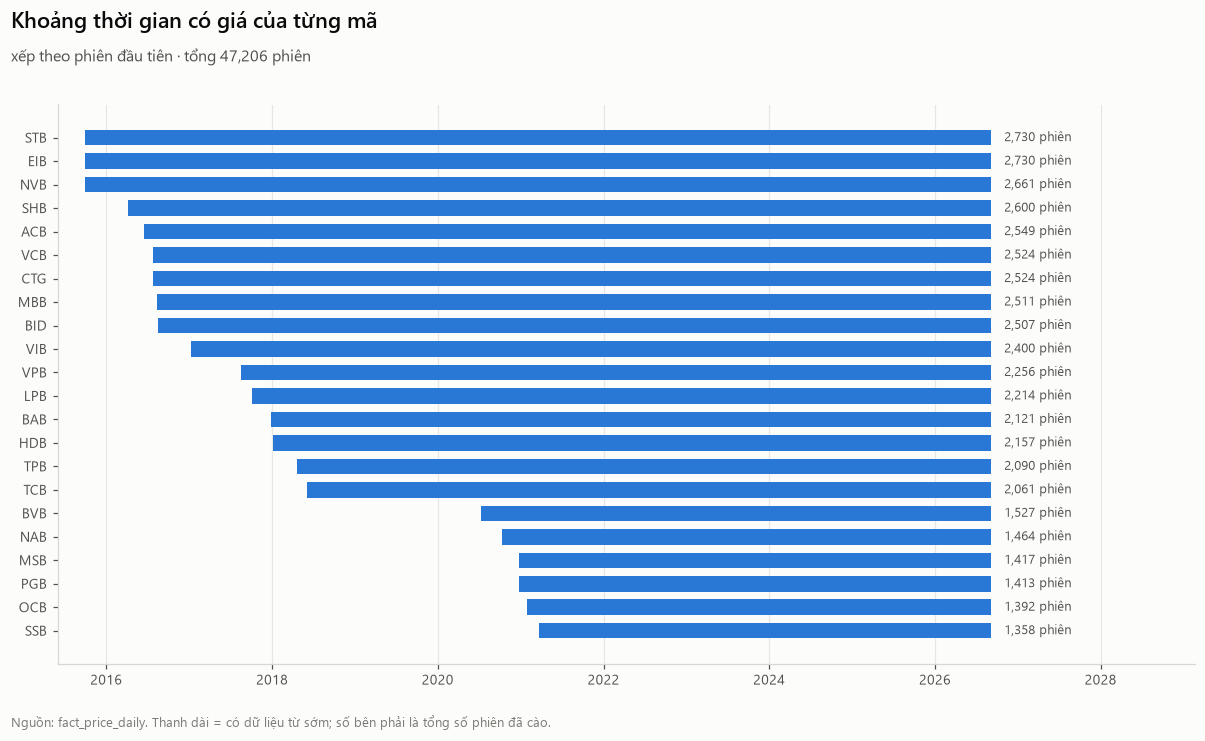

In [5]:
pv = (gia22.groupby("ticker")["date"].agg(["min", "max", "size"])
      .rename(columns={"size": "phien"}).sort_values("min"))

fig, ax = plt.subplots(figsize=(11, 6.4))
y = np.arange(len(pv))
ax.barh(y, (pv["max"] - pv["min"]).dt.days, left=pv["min"], height=0.66, color=XANH, zorder=3)
ax.set_yticks(y)
ax.set_yticklabels(pv.index, fontsize=9)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
for i, (ma, r) in enumerate(pv.iterrows()):
    ax.text(r["max"] + pd.Timedelta(days=60), i, f"{r['phien']:,} phiên",
            va="center", fontsize=8.6, color=INK_2)
ax.set_xlim(pv["min"].min() - pd.Timedelta(days=120), pv["max"].max() + pd.Timedelta(days=900))
fig.tight_layout(rect=(0, 0, 1, dau_de(fig)))
khung(fig, "Khoảng thời gian có giá của từng mã",
      f"xếp theo phiên đầu tiên · tổng {len(gia22):,} phiên",
      "Nguồn: fact_price_daily. Thanh dài = có dữ liệu từ sớm; số bên phải là tổng số phiên đã cào.")
luu(fig, "doc_01b_do_phu_gia")
plt.show()

## 2. Báo cáo tài chính — 22 ngân hàng, 2018-Q1 → 2026-Q2

Khối này có 40 chỉ tiêu thuộc 4 nhóm (cân đối kế toán, kết quả kinh doanh, lưu chuyển tiền tệ,
tỷ số). Hình đầu vẽ quy mô tổng tài sản của từng ngân hàng theo quý; hình sau cho thấy chỉ tiêu
nào thực sự có số liệu.

đã lưu → doc_02a_tong_tai_san_22nh.png


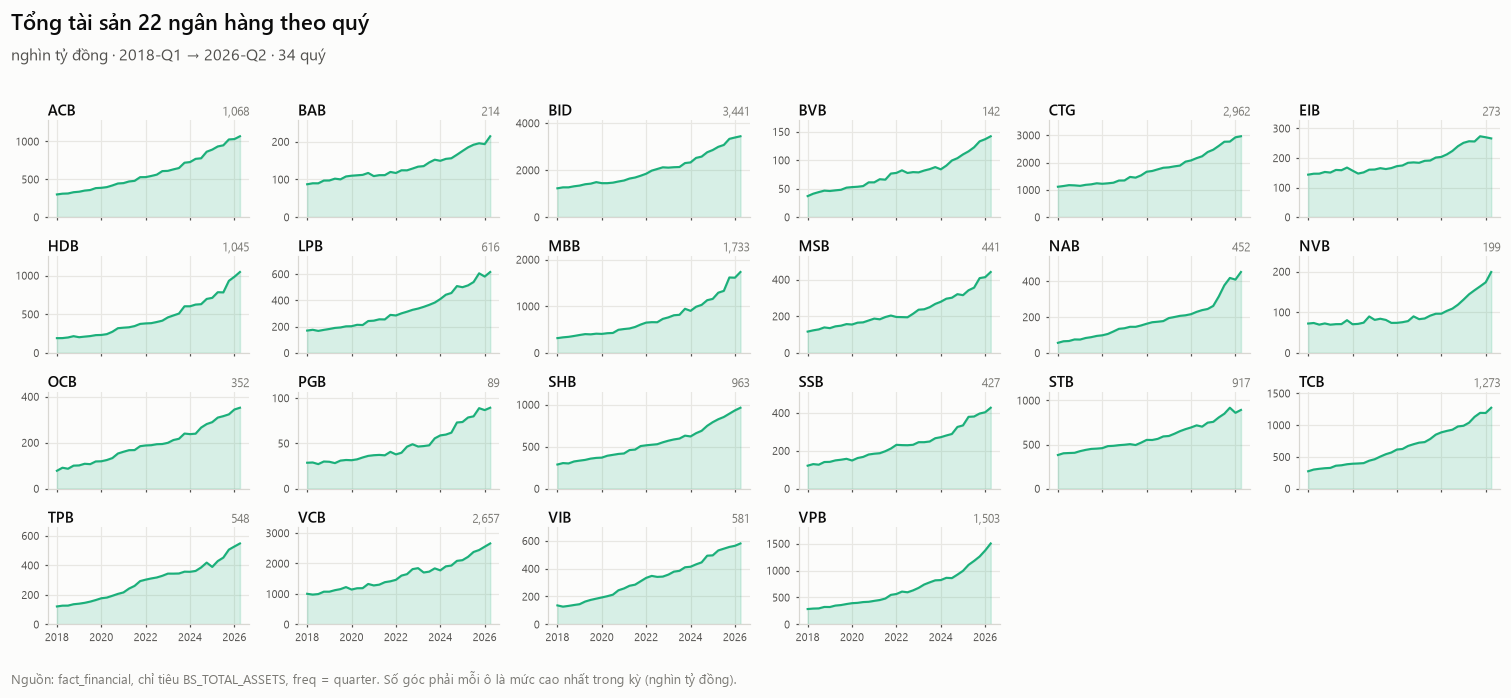

In [6]:
bctc = tai_chinh[(tai_chinh["freq"] == "quarter") & (tai_chinh["ticker"].isin(NH22))].copy()
bctc["stt"] = bctc["period"].str.replace("-Q", "").astype(int)     # 2018Q1 -> 20181, sắp đúng thứ tự
ts = (bctc[bctc["metric_id"] == "BS_TOTAL_ASSETS"]
      .pivot_table(index="period", columns="ticker", values="value", aggfunc="last")
      .sort_index())

fig, axes = luoi_nho(22, ncot=6, cao=1.5, rong=2.3, sharex=True)
x = np.arange(len(ts.index))
for ax, ma in zip(axes, NH22):
    v = nghin_ty(ts[ma].to_numpy())
    ax.fill_between(x, v, color=NGOC, alpha=0.16)
    ax.plot(x, v, lw=1.4, color=NGOC)
    ax.set_ylim(0, np.nanmax(v) * 1.2)
    ten_o(ax, ma, phu=f"{np.nanmax(v):,.0f}")
    ax.set_xticks(range(0, len(ts.index), 8))
    ax.set_xticklabels([ts.index[i][:4] for i in range(0, len(ts.index), 8)], fontsize=7.5)
fig.tight_layout(rect=(0, 0, 1, dau_de(fig)))
khung(fig, "Tổng tài sản 22 ngân hàng theo quý",
      f"nghìn tỷ đồng · {ts.index[0]} → {ts.index[-1]} · {len(ts)} quý",
      "Nguồn: fact_financial, chỉ tiêu BS_TOTAL_ASSETS, freq = quarter. Số góc phải mỗi ô là mức "
      "cao nhất trong kỳ (nghìn tỷ đồng).")
luu(fig, "doc_02a_tong_tai_san_22nh")
plt.show()

đã lưu → doc_02b_do_day_chi_tieu.png


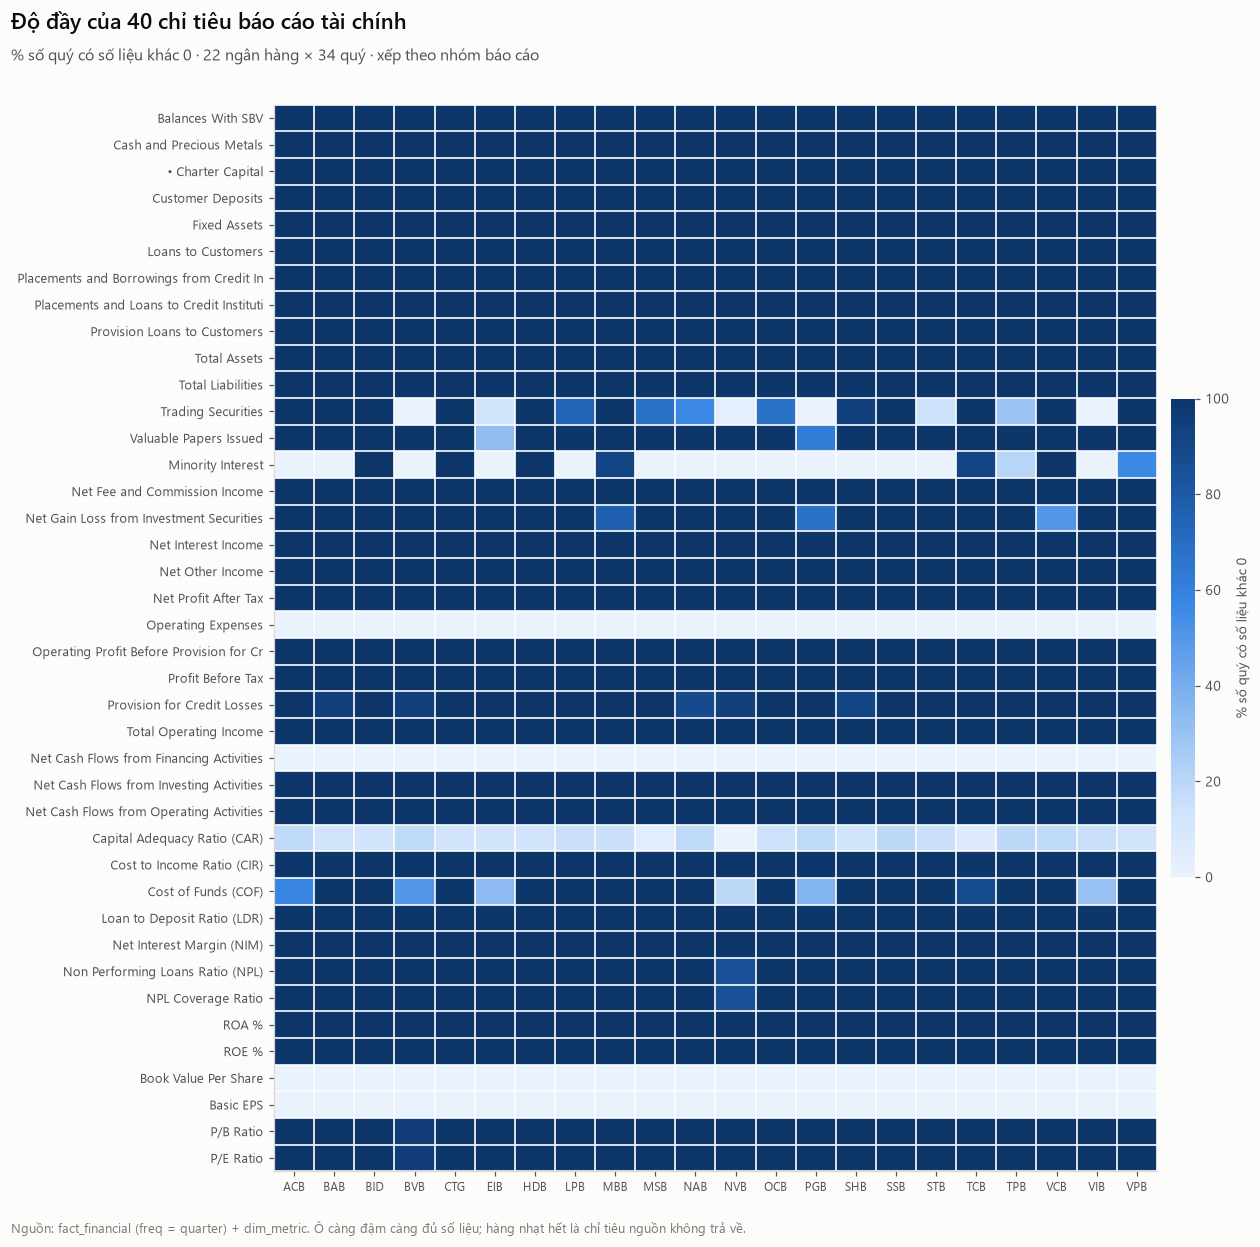

In [7]:
day = (bctc.assign(co=lambda d: d["value"].fillna(0).ne(0))
       .pivot_table(index="metric_id", columns="ticker", values="co", aggfunc="mean") * 100)
ten_ct = dict(zip(metric["metric_id"], metric["metric_name"]))
nhom = dict(zip(metric["metric_id"], metric["statement"]))
thu_tu = {"balance_sheet": 0, "income_statement": 1, "cash_flow": 2, "ratio": 3}
day = day.loc[sorted(day.index, key=lambda m: (thu_tu.get(nhom.get(m), 9), m))]
day = day[NH22]
day.index = [ten_ct.get(m, m).replace("‣", "").strip()[:40] for m in day.index]

fig, ax = plt.subplots(figsize=(11.5, 11))
im = ban_do_nhiet(ax, day, cmap=SEQ, chu=False, vmin=0, vmax=100, xoay=0)
cb = fig.colorbar(im, ax=ax, fraction=0.026, pad=0.015)
cb.set_label("% số quý có số liệu khác 0", fontsize=9, color=INK_2)
cb.outline.set_visible(False)
fig.tight_layout(rect=(0, 0, 1, dau_de(fig)))
khung(fig, "Độ đầy của 40 chỉ tiêu báo cáo tài chính",
      "% số quý có số liệu khác 0 · 22 ngân hàng × 34 quý · xếp theo nhóm báo cáo",
      "Nguồn: fact_financial (freq = quarter) + dim_metric. Ô càng đậm càng đủ số liệu; hàng nhạt "
      "hết là chỉ tiêu nguồn không trả về.")
luu(fig, "doc_02b_do_day_chi_tieu")
plt.show()

## 3. Tín dụng theo ngân hàng — 22 ngân hàng, 748 dòng quý

Dư nợ cho vay khách hàng theo quý, và hai tỷ lệ đi kèm ở quý gần nhất: LDR (dư nợ trên tiền gửi)
và tỷ lệ nợ xấu.

đã lưu → doc_03a_du_no_22nh.png


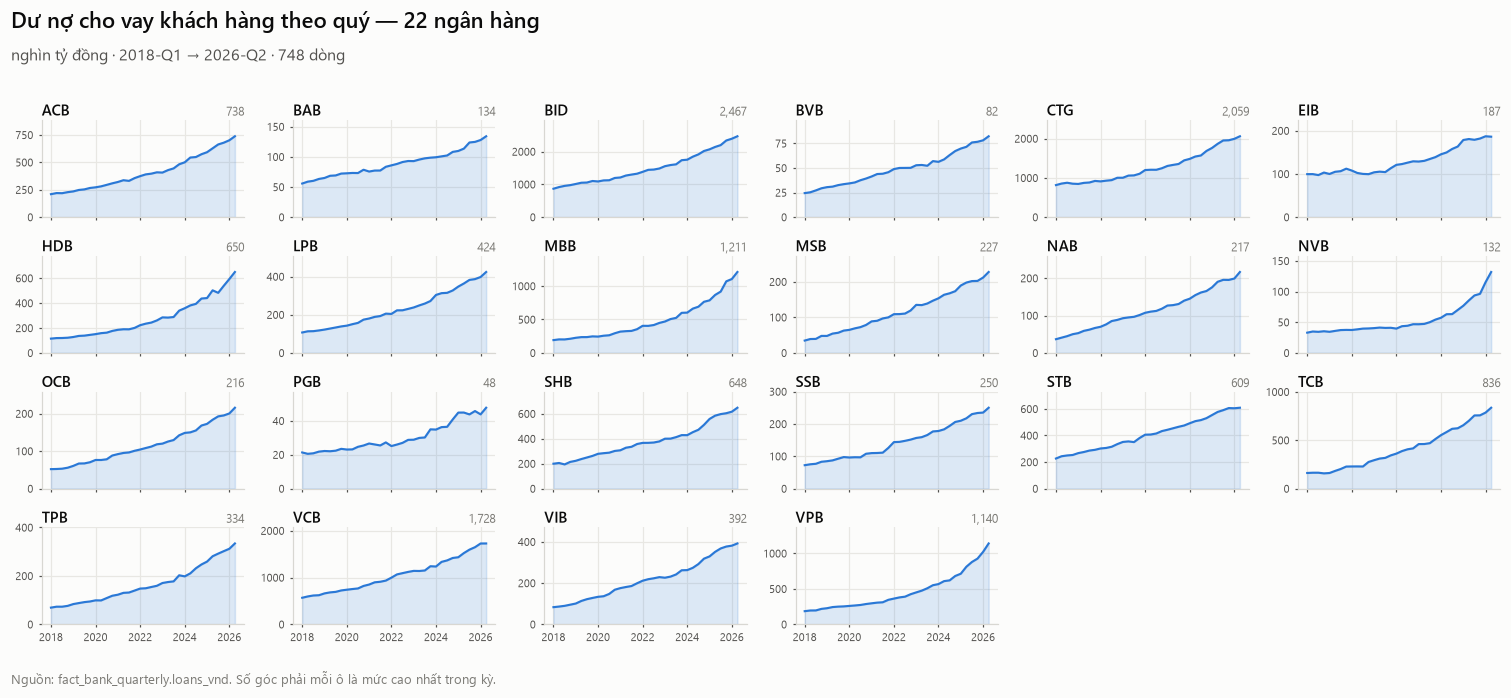

In [8]:
q22 = quy[quy["ticker"].isin(NH22)].copy()
duno = q22.pivot_table(index="period", columns="ticker", values="loans_vnd", aggfunc="last").sort_index()

fig, axes = luoi_nho(22, ncot=6, cao=1.5, rong=2.3, sharex=True)
x = np.arange(len(duno.index))
for ax, ma in zip(axes, NH22):
    v = nghin_ty(duno[ma].to_numpy())
    ax.fill_between(x, v, color=XANH, alpha=0.15)
    ax.plot(x, v, lw=1.4, color=XANH)
    ax.set_ylim(0, np.nanmax(v) * 1.2)
    ten_o(ax, ma, phu=f"{np.nanmax(v):,.0f}")
    ax.set_xticks(range(0, len(duno.index), 8))
    ax.set_xticklabels([duno.index[i][:4] for i in range(0, len(duno.index), 8)], fontsize=7.5)
fig.tight_layout(rect=(0, 0, 1, dau_de(fig)))
khung(fig, "Dư nợ cho vay khách hàng theo quý — 22 ngân hàng",
      f"nghìn tỷ đồng · {duno.index[0]} → {duno.index[-1]} · {len(q22):,} dòng",
      "Nguồn: fact_bank_quarterly.loans_vnd. Số góc phải mỗi ô là mức cao nhất trong kỳ.")
luu(fig, "doc_03a_du_no_22nh")
plt.show()

đã lưu → doc_03b_ldr_npl.png


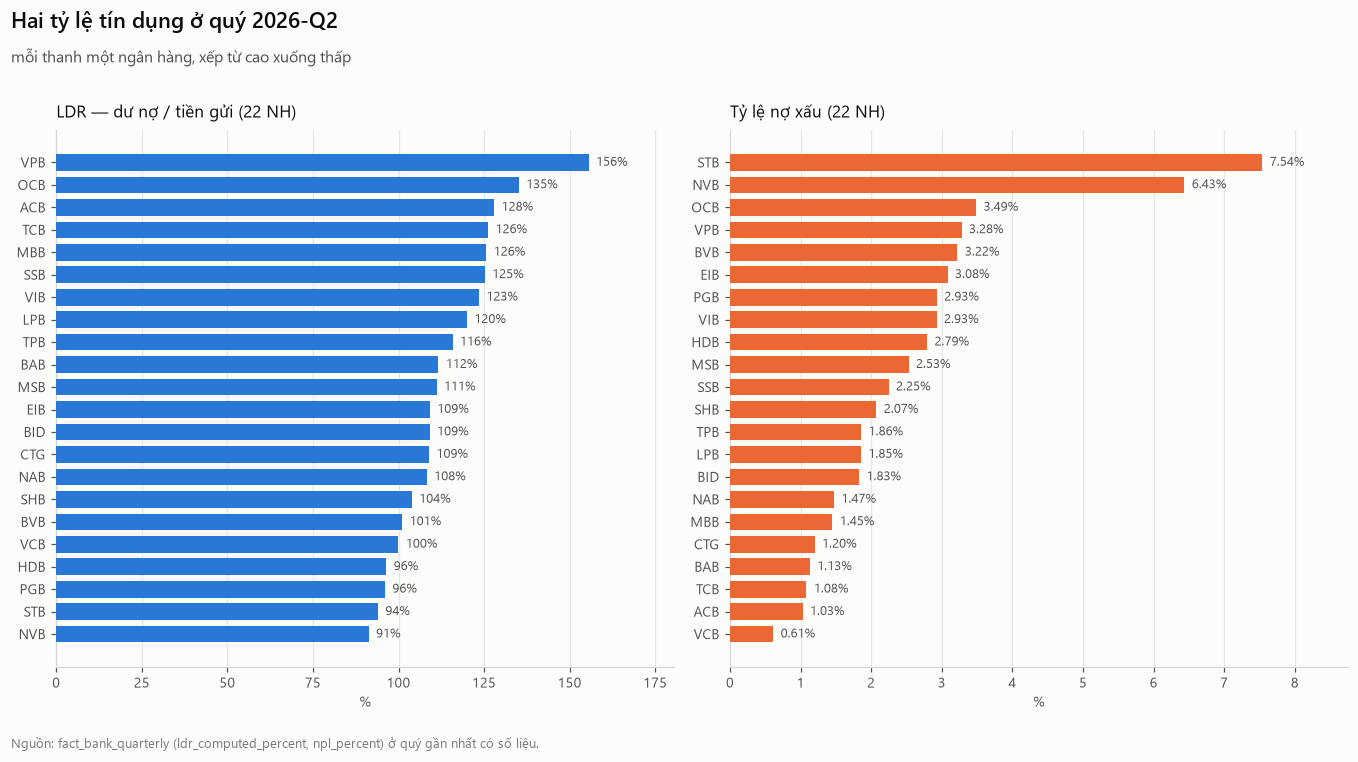

In [9]:
ky = sorted(q22["period"].unique())[-1]
gan = q22[q22["period"] == ky].set_index("ticker")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.4, 6.6))
d1 = gan["ldr_computed_percent"].dropna().sort_values(ascending=False)
thanh_ngang(ax1, d1.index, d1.to_numpy(), mau=XANH, dinh_dang="{:.0f}", don_vi="%")
ax1.set_title(f"LDR — dư nợ / tiền gửi ({len(d1)} NH)", fontsize=11, loc="left", pad=8)
ax1.set_xlabel("%", fontsize=9)

d2 = gan["npl_percent"].dropna().sort_values(ascending=False)
thanh_ngang(ax2, d2.index, d2.to_numpy(), mau=CAM, dinh_dang="{:.2f}", don_vi="%")
ax2.set_title(f"Tỷ lệ nợ xấu ({len(d2)} NH)", fontsize=11, loc="left", pad=8)
ax2.set_xlabel("%", fontsize=9)

fig.tight_layout(rect=(0, 0, 1, dau_de(fig)))
khung(fig, f"Hai tỷ lệ tín dụng ở quý {ky}",
      "mỗi thanh một ngân hàng, xếp từ cao xuống thấp",
      "Nguồn: fact_bank_quarterly (ldr_computed_percent, npl_percent) ở quý gần nhất có số liệu.")
luu(fig, "doc_03b_ldr_npl")
plt.show()

## 4. Chi phí vốn (COF) — 22 ngân hàng, 2018-Q1 → 2026-Q2

Một ô = một ngân hàng ở một quý; màu càng đậm, chi phí vốn càng cao. Ô trắng là quý không có số
liệu. Cách vẽ này xem được cả 22 ngân hàng × 33 quý trong một hình.

đã lưu → doc_04_chi_phi_von.png


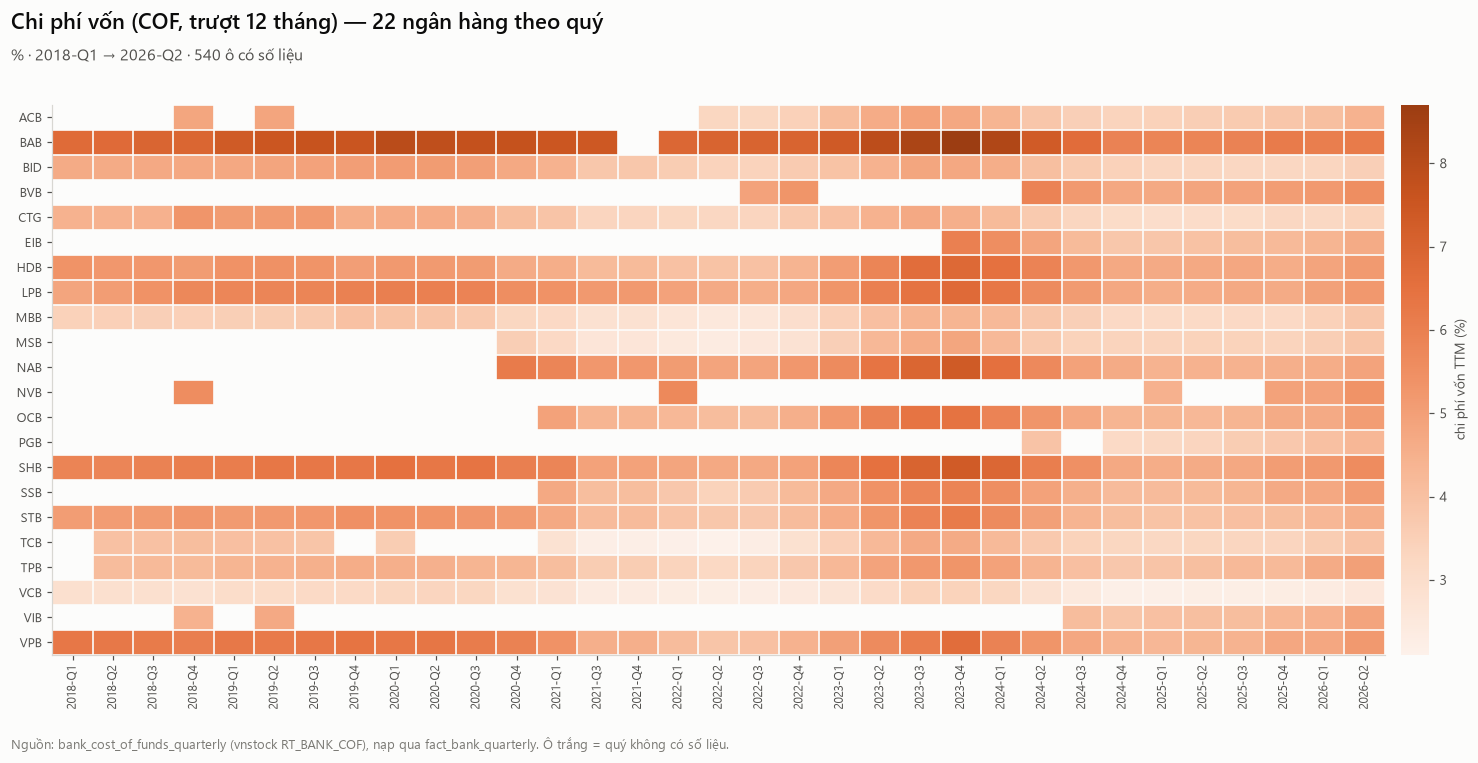

In [10]:
M_cof = (quy[quy["ticker"].isin(NH22)]
         .pivot_table(index="ticker", columns="period", values="cof_ttm_percent", aggfunc="last")
         .reindex(NH22).dropna(axis=1, how="all"))

fig, ax = plt.subplots(figsize=(13.5, 6.6))
im = ban_do_nhiet(ax, M_cof, cmap=SEQ_CAM, chu=False, moi_nhan_x=1)
cb = fig.colorbar(im, ax=ax, fraction=0.02, pad=0.012)
cb.set_label("chi phí vốn TTM (%)", fontsize=9, color=INK_2)
cb.outline.set_visible(False)
fig.tight_layout(rect=(0, 0, 1, dau_de(fig)))
khung(fig, "Chi phí vốn (COF, trượt 12 tháng) — 22 ngân hàng theo quý",
      f"% · {M_cof.columns[0]} → {M_cof.columns[-1]} · {int(M_cof.notna().sum().sum())} ô có số liệu",
      "Nguồn: bank_cost_of_funds_quarterly (vnstock RT_BANK_COF), nạp qua fact_bank_quarterly."
      " Ô trắng = quý không có số liệu.")
luu(fig, "doc_04_chi_phi_von")
plt.show()

## 5. Lợi suất tài sản sinh lời — 22 ngân hàng, 2018-Q1 → 2026-Q2

Hai đường cùng đơn vị phần trăm nên vẽ chung một ô được: đường trên là lợi suất tài sản sinh lời,
đường dưới là chi phí vốn, phần tô giữa hai đường chính là biên lãi thuần (NIM).

đã lưu → doc_05_loi_suat_tssl.png


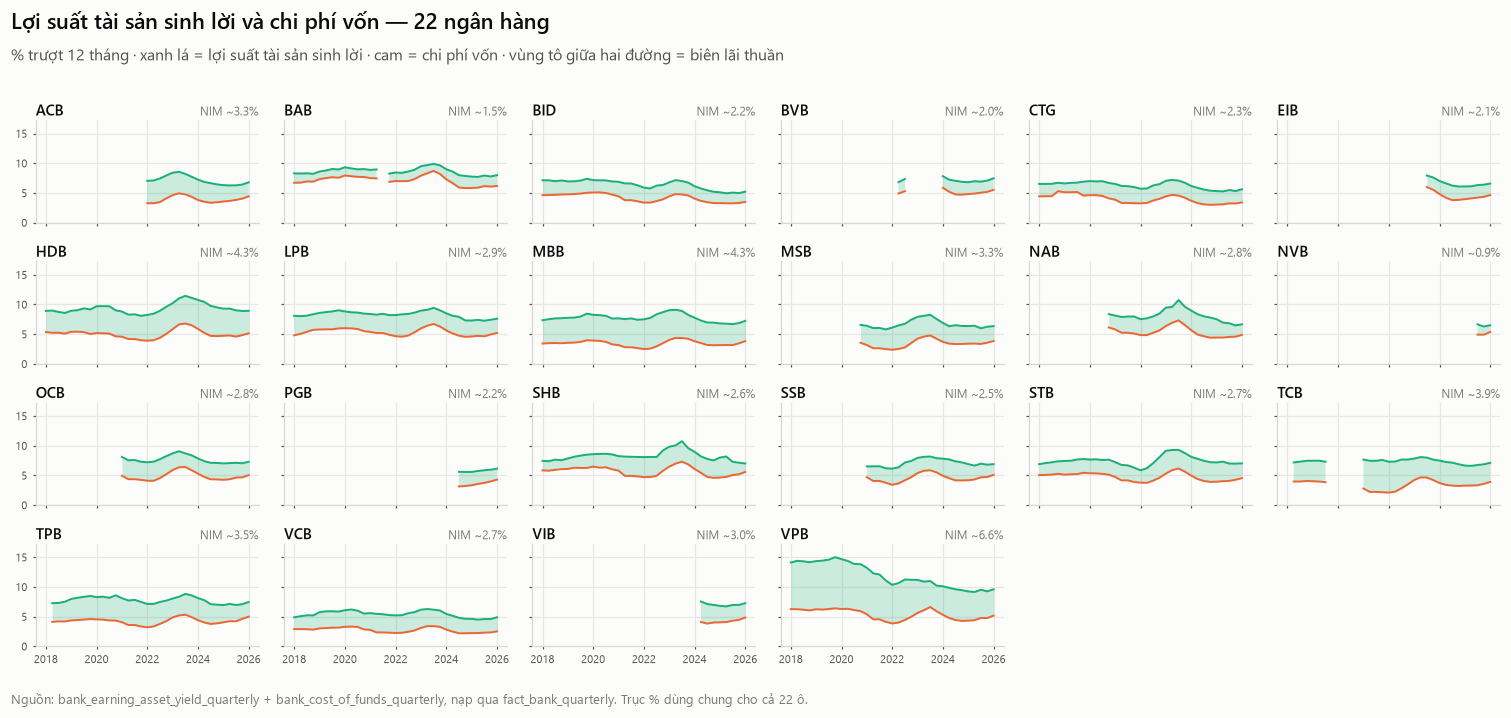

In [11]:
qy = quy[quy["ticker"].isin(NH22)].copy()
Y = qy.pivot_table(index="period", columns="ticker", values="earning_asset_yield_ttm_percent",
                   aggfunc="last").sort_index()
C = qy.pivot_table(index="period", columns="ticker", values="cof_ttm_percent", aggfunc="last").sort_index()
Y, C = Y.align(C, join="inner")
giu = Y.notna().any(axis=1)
Y, C = Y[giu], C[giu]

fig, axes = luoi_nho(22, ncot=6, cao=1.55, rong=2.3, sharex=True, sharey=True)
x = np.arange(len(Y.index))
for ax, ma in zip(axes, NH22):
    y1, y2 = Y[ma].to_numpy(dtype=float), C[ma].to_numpy(dtype=float)
    ax.fill_between(x, y2, y1, where=~np.isnan(y1), color=NGOC, alpha=0.22, lw=0)
    ax.plot(x, y1, lw=1.3, color=NGOC)
    ax.plot(x, y2, lw=1.3, color=CAM)
    nim = np.nanmean(y1 - y2)
    ten_o(ax, ma, phu=f"NIM ~{nim:.1f}%")
    ax.set_xticks(range(0, len(Y.index), 8))
    ax.set_xticklabels([Y.index[i][:4] for i in range(0, len(Y.index), 8)], fontsize=7.5)
axes[0].set_ylim(0, np.nanmax(Y.to_numpy(dtype=float)) * 1.15)
fig.tight_layout(rect=(0, 0, 1, dau_de(fig)))
khung(fig, "Lợi suất tài sản sinh lời và chi phí vốn — 22 ngân hàng",
      "% trượt 12 tháng · xanh lá = lợi suất tài sản sinh lời · cam = chi phí vốn · "
      "vùng tô giữa hai đường = biên lãi thuần",
      "Nguồn: bank_earning_asset_yield_quarterly + bank_cost_of_funds_quarterly, nạp qua "
      "fact_bank_quarterly. Trục % dùng chung cho cả 22 ô.")
luu(fig, "doc_05_loi_suat_tssl")
plt.show()

## 6. CPI — 2017-07 → 2026-07

Hai panel dùng chung trục thời gian: so với cùng kỳ năm trước (đường) và so với tháng liền trước
(cột). Không dùng hai trục y chồng lên nhau vì hai thang khác nhau.

đã lưu → doc_06_cpi.png


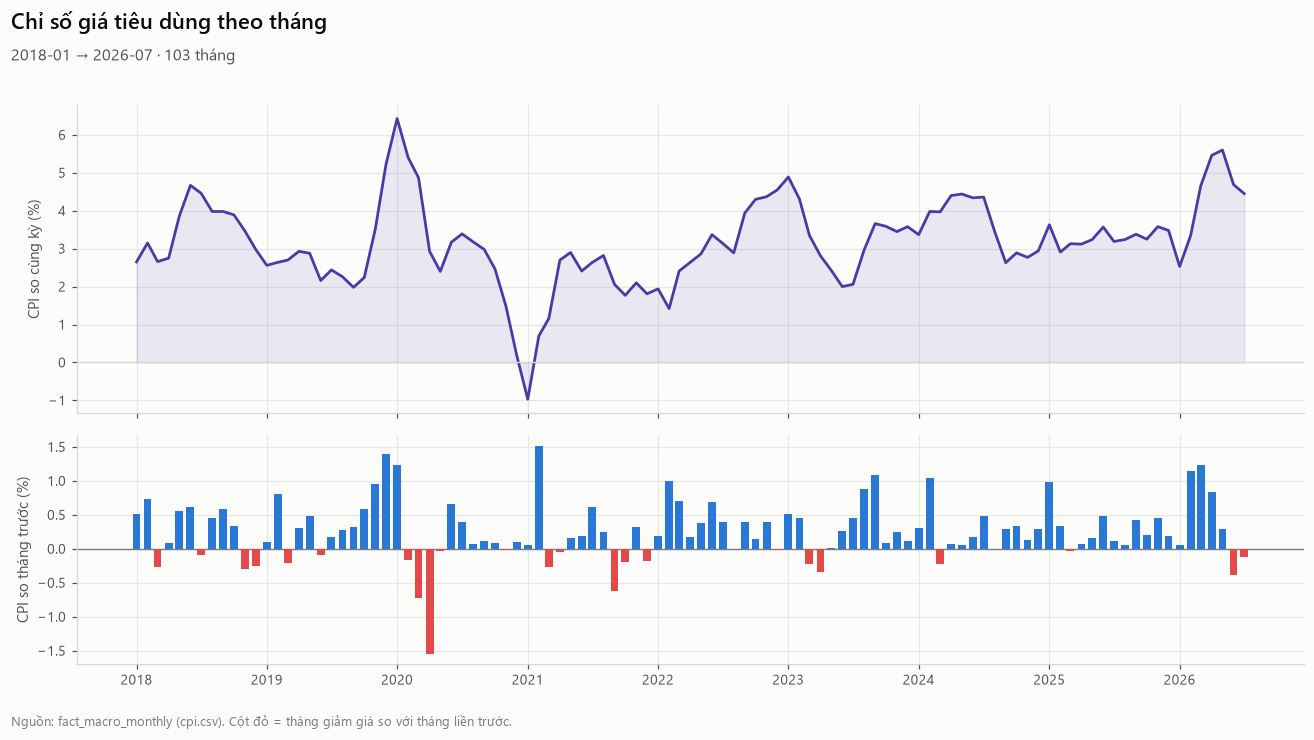

In [12]:
cpi = vi_mo.dropna(subset=["cpi_yoy_percent"]).sort_values("month_date")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6.4), sharex=True,
                               gridspec_kw={"height_ratios": [1.35, 1]})
ax1.plot(cpi["month_date"], cpi["cpi_yoy_percent"], lw=1.8, color=TIM)
ax1.fill_between(cpi["month_date"], cpi["cpi_yoy_percent"], color=TIM, alpha=0.10)
ax1.set_ylabel("CPI so cùng kỳ (%)", fontsize=9.5)
ax1.axhline(0, color=AXIS, lw=0.9)

mom = vi_mo.dropna(subset=["cpi_mom_percent"])
ax2.bar(mom["month_date"], mom["cpi_mom_percent"], width=22,
        color=np.where(mom["cpi_mom_percent"] >= 0, XANH, DO), zorder=3)
ax2.axhline(0, color=INK_3, lw=0.9)
ax2.set_ylabel("CPI so tháng trước (%)", fontsize=9.5)

fig.tight_layout(rect=(0, 0, 1, dau_de(fig)))
khung(fig, "Chỉ số giá tiêu dùng theo tháng",
      f"{cpi['month'].iloc[0]} → {cpi['month'].iloc[-1]} · {len(cpi)} tháng",
      "Nguồn: fact_macro_monthly (cpi.csv). Cột đỏ = tháng giảm giá so với tháng liền trước.")
luu(fig, "doc_06_cpi")
plt.show()

## 7. Tăng trưởng tín dụng toàn hệ thống — 2018 → 2025

Tám năm, tám cột, ghi thẳng con số lên đầu cột.

đã lưu → doc_07_tang_truong_tin_dung.png


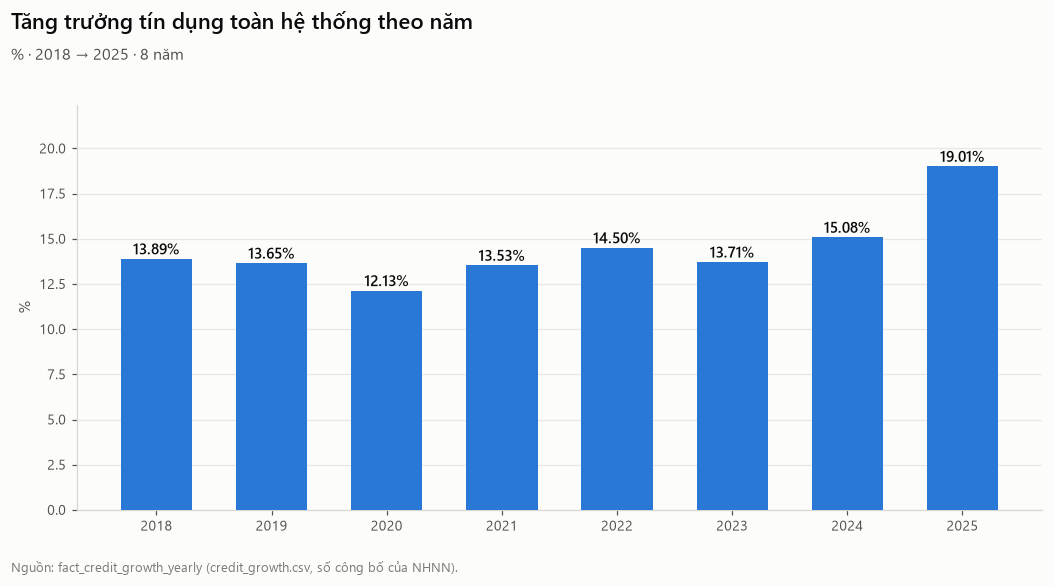

In [13]:
tt = tin_dung_nam.sort_values("year")

fig, ax = plt.subplots(figsize=(9.6, 5))
ax.bar(tt["year"].astype(int).astype(str), tt["credit_growth_percent"], width=0.62,
       color=XANH, zorder=3)
for x, v in zip(tt["year"].astype(int).astype(str), tt["credit_growth_percent"]):
    ax.text(x, v + 0.25, f"{v:.2f}%", ha="center", fontsize=10, color=INK, fontweight="600")
ax.set_ylim(0, tt["credit_growth_percent"].max() * 1.18)
ax.set_ylabel("%", fontsize=9.5)
ax.grid(axis="x", visible=False)

fig.tight_layout(rect=(0, 0, 1, dau_de(fig)))
khung(fig, "Tăng trưởng tín dụng toàn hệ thống theo năm",
      f"% · {int(tt['year'].min())} → {int(tt['year'].max())} · {len(tt)} năm",
      "Nguồn: fact_credit_growth_yearly (credit_growth.csv, số công bố của NHNN).")
luu(fig, "doc_07_tang_truong_tin_dung")
plt.show()

## 8. Lãi suất điều hành của Ngân hàng Nhà nước — 2017-07 → 2023-06

Lãi suất điều hành giữ nguyên giữa hai lần công bố nên vẽ dạng bậc thang, không nối xiên. Mỗi
chấm là một lần thay đổi có hiệu lực.

đã lưu → doc_08_lai_suat_dieu_hanh.png


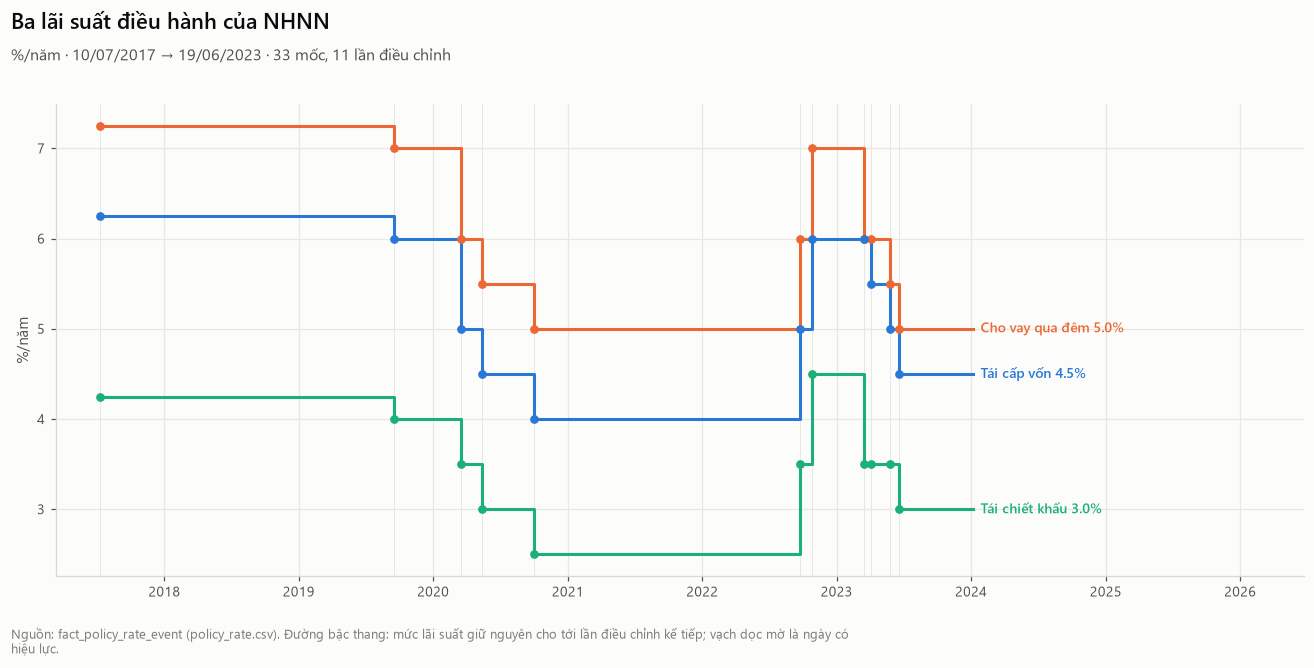

In [14]:
dh = dieu_hanh.sort_values("date_effective")
ten_ls = {"tai_cap_von": "Tái cấp vốn", "tai_chiet_khau": "Tái chiết khấu",
          "cho_vay_qua_dem": "Cho vay qua đêm"}
mau_ls = {"tai_cap_von": XANH, "tai_chiet_khau": NGOC, "cho_vay_qua_dem": CAM}

fig, ax = plt.subplots(figsize=(12, 5.6))
cuoi = dh["date_effective"].max() + pd.Timedelta(days=200)
for loai, d in dh.groupby("rate_type"):
    d = d.sort_values("date_effective")
    xs = list(d["date_effective"]) + [cuoi]
    ys = list(d["rate_percent"]) + [d["rate_percent"].iloc[-1]]
    ax.step(xs, ys, where="post", lw=2, color=mau_ls[loai], label=ten_ls[loai])
    ax.scatter(d["date_effective"], d["rate_percent"], s=22, color=mau_ls[loai], zorder=4)
    ax.text(cuoi, d["rate_percent"].iloc[-1], f"  {ten_ls[loai]} {d['rate_percent'].iloc[-1]:.1f}%",
            va="center", fontsize=9, color=mau_ls[loai], fontweight="600")
for ngay in sorted(dh["date_effective"].unique()):
    ax.axvline(ngay, color=GRID, lw=0.7, zorder=0)
ax.set_ylabel("%/năm", fontsize=9.5)
ax.set_xlim(dh["date_effective"].min() - pd.Timedelta(days=120), cuoi + pd.Timedelta(days=900))

fig.tight_layout(rect=(0, 0, 1, dau_de(fig)))
khung(fig, "Ba lãi suất điều hành của NHNN",
      f"%/năm · {dh['date_effective'].min():%d/%m/%Y} → {dh['date_effective'].max():%d/%m/%Y} · "
      f"{len(dh)} mốc, {dh['date_effective'].nunique()} lần điều chỉnh",
      "Nguồn: fact_policy_rate_event (policy_rate.csv). Đường bậc thang: mức lãi suất giữ nguyên "
      "cho tới lần điều chỉnh kế tiếp; vạch dọc mờ là ngày có hiệu lực.")
luu(fig, "doc_08_lai_suat_dieu_hanh")
plt.show()

## 9. Bình quân ngành theo công bố của NHNN — 2024-01 → 2026-07

Mỗi kỳ hạn là một dải min–max theo tháng: vùng tô là khoảng NHNN công bố, đường giữa là trung
điểm của khoảng đó.

đã lưu → doc_09_binh_quan_nganh.png


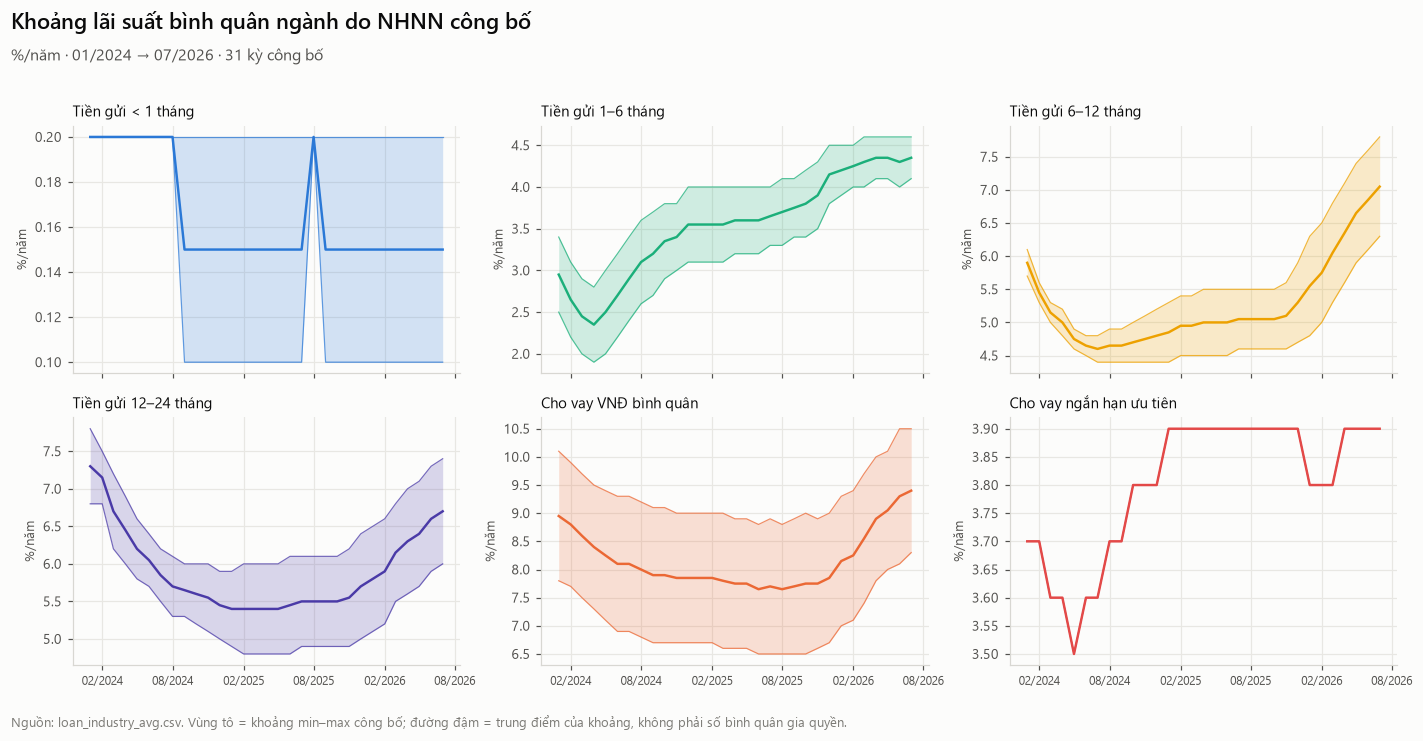

In [15]:
if CO_NGANH:
    ng = nganh.sort_values("date")
    dai = [("deposit_0_to_1m", "Tiền gửi < 1 tháng", XANH),
           ("deposit_1_to_6m", "Tiền gửi 1–6 tháng", NGOC),
           ("deposit_6_to_12m", "Tiền gửi 6–12 tháng", VANG),
           ("deposit_12_to_24m", "Tiền gửi 12–24 tháng", TIM),
           ("loan_vnd_avg", "Cho vay VNĐ bình quân", CAM),
           ("loan_priority_short_term", "Cho vay ngắn hạn ưu tiên", DO)]

    fig, axes = plt.subplots(2, 3, figsize=(13, 6.4), sharex=True)
    for ax, (cot, nhan, mau) in zip(axes.ravel(), dai):
        lo, hi = ng[cot + "_min"], ng[cot + "_max"]
        ax.fill_between(ng["date"], lo, hi, color=mau, alpha=0.20, lw=0)
        ax.plot(ng["date"], (lo + hi) / 2, lw=1.6, color=mau)
        ax.plot(ng["date"], lo, lw=0.8, color=mau, alpha=0.75)
        ax.plot(ng["date"], hi, lw=0.8, color=mau, alpha=0.75)
        ax.set_title(nhan, fontsize=10, loc="left", pad=6, color=INK)
        ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
        ax.tick_params(axis="x", rotation=0, labelsize=8)
        ax.set_ylabel("%/năm", fontsize=8.5)
    fig.tight_layout(rect=(0, 0, 1, dau_de(fig)))
    khung(fig, "Khoảng lãi suất bình quân ngành do NHNN công bố",
          f"%/năm · {ng['date'].min():%m/%Y} → {ng['date'].max():%m/%Y} · {len(ng)} kỳ công bố",
          "Nguồn: loan_industry_avg.csv. Vùng tô = khoảng min–max công bố; đường đậm = trung điểm "
          "của khoảng, không phải số bình quân gia quyền.")
    luu(fig, "doc_09_binh_quan_nganh")
    plt.show()
else:
    print("Thiếu data/loan_rates/loan_industry_avg.csv — bỏ qua mục 9.")

## 10. Lãi suất cho vay theo ngân hàng — 2025-01 → 2026-07

Dữ liệu thưa: mỗi ngân hàng chỉ công bố ở một số tháng. Bản đồ nhiệt cho thấy đúng tháng nào có
số và số đó là bao nhiêu — ô trắng nghĩa là tháng đó ngân hàng không công bố.

đã lưu → doc_10_lai_suat_cho_vay.png


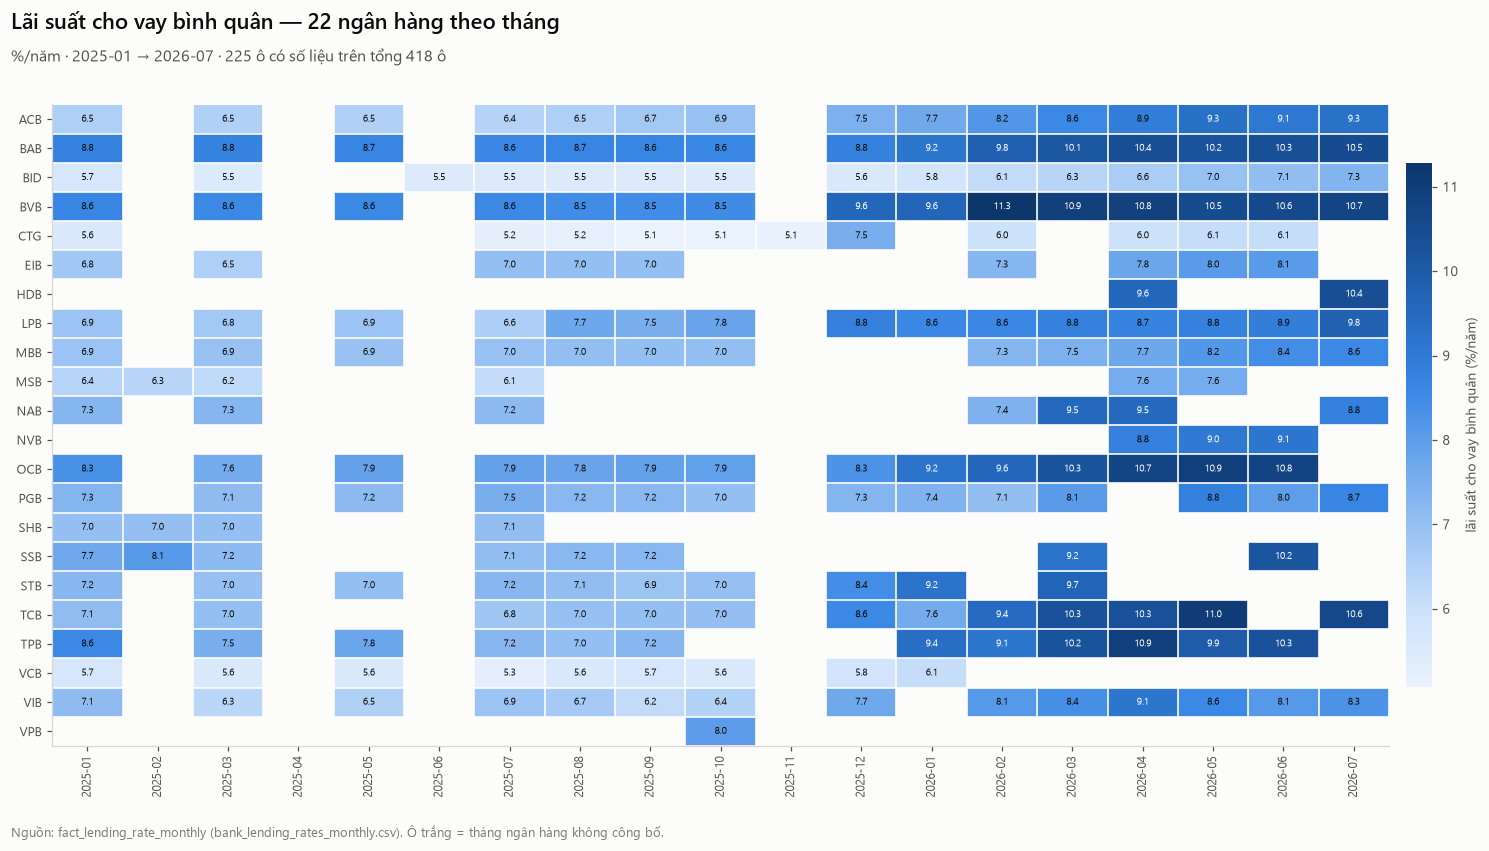

In [16]:
cv = cho_vay[cho_vay["ticker"].isin(NH22)].copy()
# Trục tháng phải liền mạch: tháng không ngân hàng nào công bố vẫn phải là một cột trống,
# nếu không trục thời gian sẽ nhảy cóc.
moc = pd.period_range(cv["month_date"].min(), cv["month_date"].max(), freq="M").astype(str)
M_cv = (cv.pivot_table(index="ticker", columns="month", values="lending_avg_percent", aggfunc="mean")
        .reindex(index=NH22, columns=moc))

fig, ax = plt.subplots(figsize=(13.6, 7.4))
im = ban_do_nhiet(ax, M_cv, cmap=SEQ, dinh_dang="{:.1f}", chu=True, co_chu=6.6, xoay=90)
cb = fig.colorbar(im, ax=ax, fraction=0.019, pad=0.012)
cb.set_label("lãi suất cho vay bình quân (%/năm)", fontsize=9, color=INK_2)
cb.outline.set_visible(False)
fig.tight_layout(rect=(0, 0, 1, dau_de(fig)))
khung(fig, f"Lãi suất cho vay bình quân — {M_cv.notna().any(axis=1).sum()} ngân hàng theo tháng",
      f"%/năm · {M_cv.columns[0]} → {M_cv.columns[-1]} · {int(M_cv.notna().sum().sum())} ô có số liệu "
      f"trên tổng {M_cv.size} ô",
      "Nguồn: fact_lending_rate_monthly (bank_lending_rates_monthly.csv). Ô trắng = tháng ngân "
      "hàng không công bố.")
luu(fig, "doc_10_lai_suat_cho_vay")
plt.show()

## 11. Lãi suất tiết kiệm niêm yết — 17 ngân hàng niêm yết

Nguồn `laisuattietkiem` được cào theo ngày. Hình dưới lấy **ngày cào gần nhất**, bày đủ 8 kỳ hạn
cho hai kênh gửi: tại quầy và online.

đã lưu → doc_11a_lai_suat_tiet_kiem.png


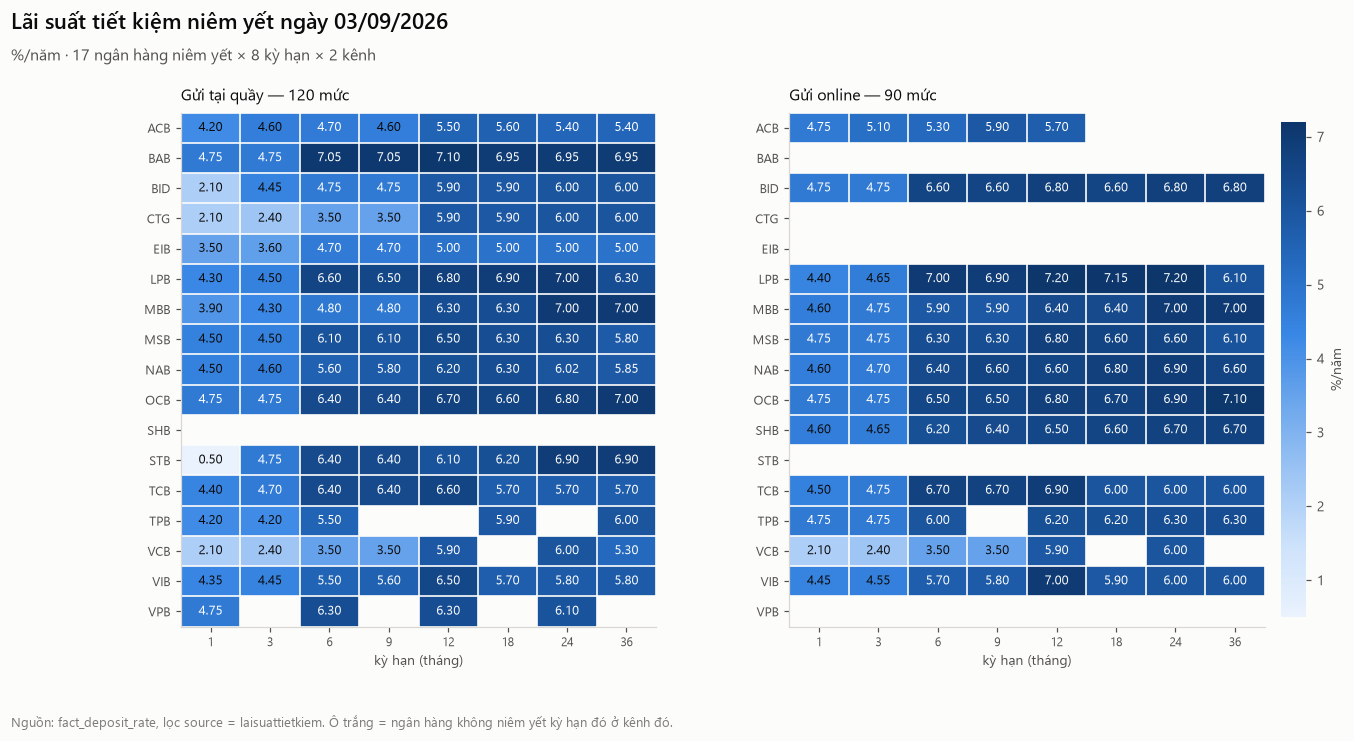

In [17]:
lstk = tiet_kiem[(tiet_kiem["source"] == "laisuattietkiem") & (tiet_kiem["ticker"].isin(NH22))]
ngay_moi = lstk["date"].max()
hom_nay = lstk[lstk["date"] == ngay_moi]
NH17 = sorted(hom_nay["ticker"].unique())
KY_HAN = sorted(hom_nay["term_months"].unique())

fig, axes = plt.subplots(1, 2, figsize=(13.2, 6.4))
fig.subplots_adjust(top=dau_de(fig) - 0.035, wspace=0.28)
ims = []
for ax, kenh, nhan in zip(axes, ["quay", "online"], ["Gửi tại quầy", "Gửi online"]):
    M = (hom_nay[hom_nay["channel"] == kenh]
         .pivot_table(index="ticker", columns="term_months", values="rate_percent", aggfunc="mean")
         .reindex(index=NH17, columns=KY_HAN))
    im = ban_do_nhiet(ax, M, cmap=SEQ, dinh_dang="{:.2f}", chu=True, co_chu=8.2, xoay=0,
                      vmin=hom_nay["rate_percent"].min(), vmax=hom_nay["rate_percent"].max())
    ims.append(im)
    ax.set_title(f"{nhan} — {int(M.notna().sum().sum())} mức", fontsize=10.5, loc="left", pad=8)
    ax.set_xlabel("kỳ hạn (tháng)", fontsize=9)
cb = fig.colorbar(ims[0], ax=axes, fraction=0.022, pad=0.015)
cb.set_label("%/năm", fontsize=9, color=INK_2)
cb.outline.set_visible(False)
khung(fig, f"Lãi suất tiết kiệm niêm yết ngày {ngay_moi:%d/%m/%Y}",
      f"%/năm · {len(NH17)} ngân hàng niêm yết × {len(KY_HAN)} kỳ hạn × 2 kênh",
      "Nguồn: fact_deposit_rate, lọc source = laisuattietkiem. Ô trắng = ngân hàng không niêm yết "
      "kỳ hạn đó ở kênh đó.")
luu(fig, "doc_11a_lai_suat_tiet_kiem")
plt.show()

Vì nguồn này cào liên tục theo ngày, phần dưới cho thấy toàn bộ số ngày đã cào được — mỗi ô một
ngân hàng, ba kỳ hạn phổ biến, kênh online.

đã lưu → doc_11b_lai_suat_tiet_kiem_theo_ngay.png


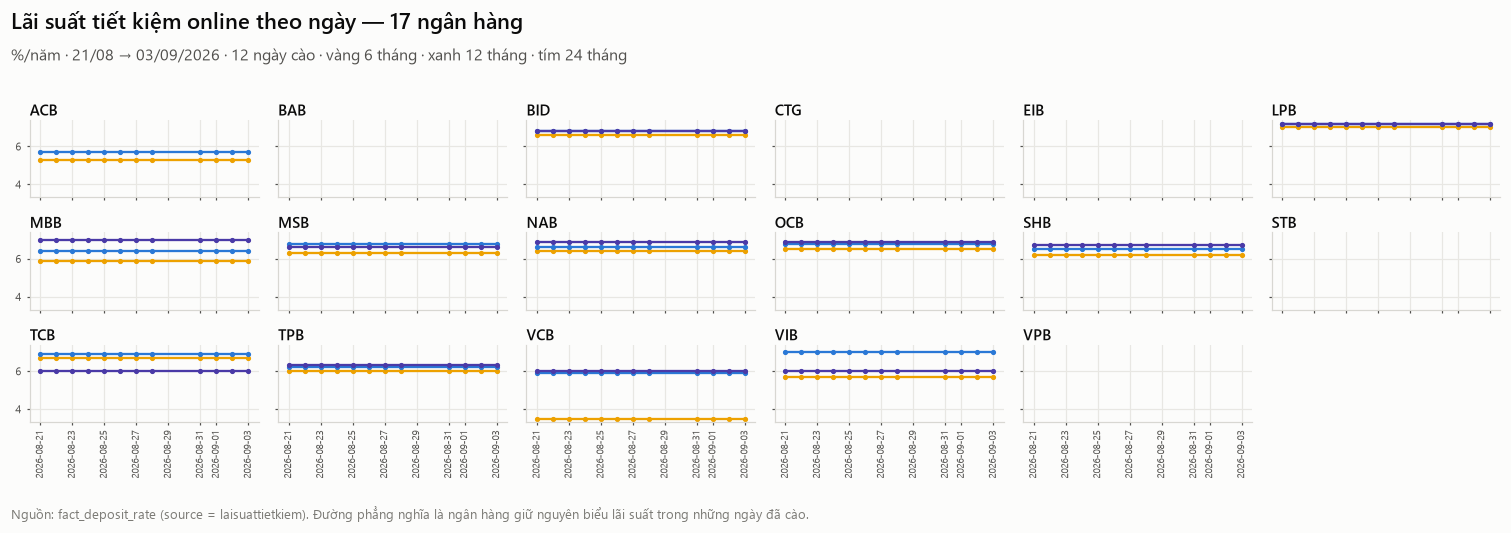

In [18]:
chuoi = lstk[(lstk["channel"] == "online") & (lstk["term_months"].isin([6, 12, 24]))]
mau_kh = {6: VANG, 12: XANH, 24: TIM}

fig, axes = luoi_nho(len(NH17), ncot=6, cao=1.5, rong=2.3, sharex=True, sharey=True)
for ax, ma in zip(axes, NH17):
    d = chuoi[chuoi["ticker"] == ma]
    for kh, dd in d.groupby("term_months"):
        dd = dd.sort_values("date")
        ax.plot(dd["date"], dd["rate_percent"], lw=1.5, color=mau_kh[kh], marker="o", ms=2.4)
    ten_o(ax, ma)
    ax.tick_params(axis="x", rotation=90, labelsize=6.5)
fig.tight_layout(rect=(0, 0, 1, dau_de(fig)))
khung(fig, f"Lãi suất tiết kiệm online theo ngày — {len(NH17)} ngân hàng",
      f"%/năm · {lstk['date'].min():%d/%m} → {lstk['date'].max():%d/%m/%Y} · "
      f"{lstk['date'].nunique()} ngày cào · vàng 6 tháng · xanh 12 tháng · tím 24 tháng",
      "Nguồn: fact_deposit_rate (source = laisuattietkiem). Đường phẳng nghĩa là ngân hàng giữ "
      "nguyên biểu lãi suất trong những ngày đã cào.")
luu(fig, "doc_11b_lai_suat_tiet_kiem_theo_ngay")
plt.show()

## 12. Harvard Dataverse — 45 ngân hàng, 2002 → 2022

Bộ dữ liệu mở rộng có 50 cột. Hình đầu đếm xem mỗi ngân hàng ở mỗi năm có bao nhiêu chỉ tiêu điền
được; hình sau vẽ số chi nhánh của **cả 45 ngân hàng**.

đã lưu → doc_12a_do_phu_dataverse.png


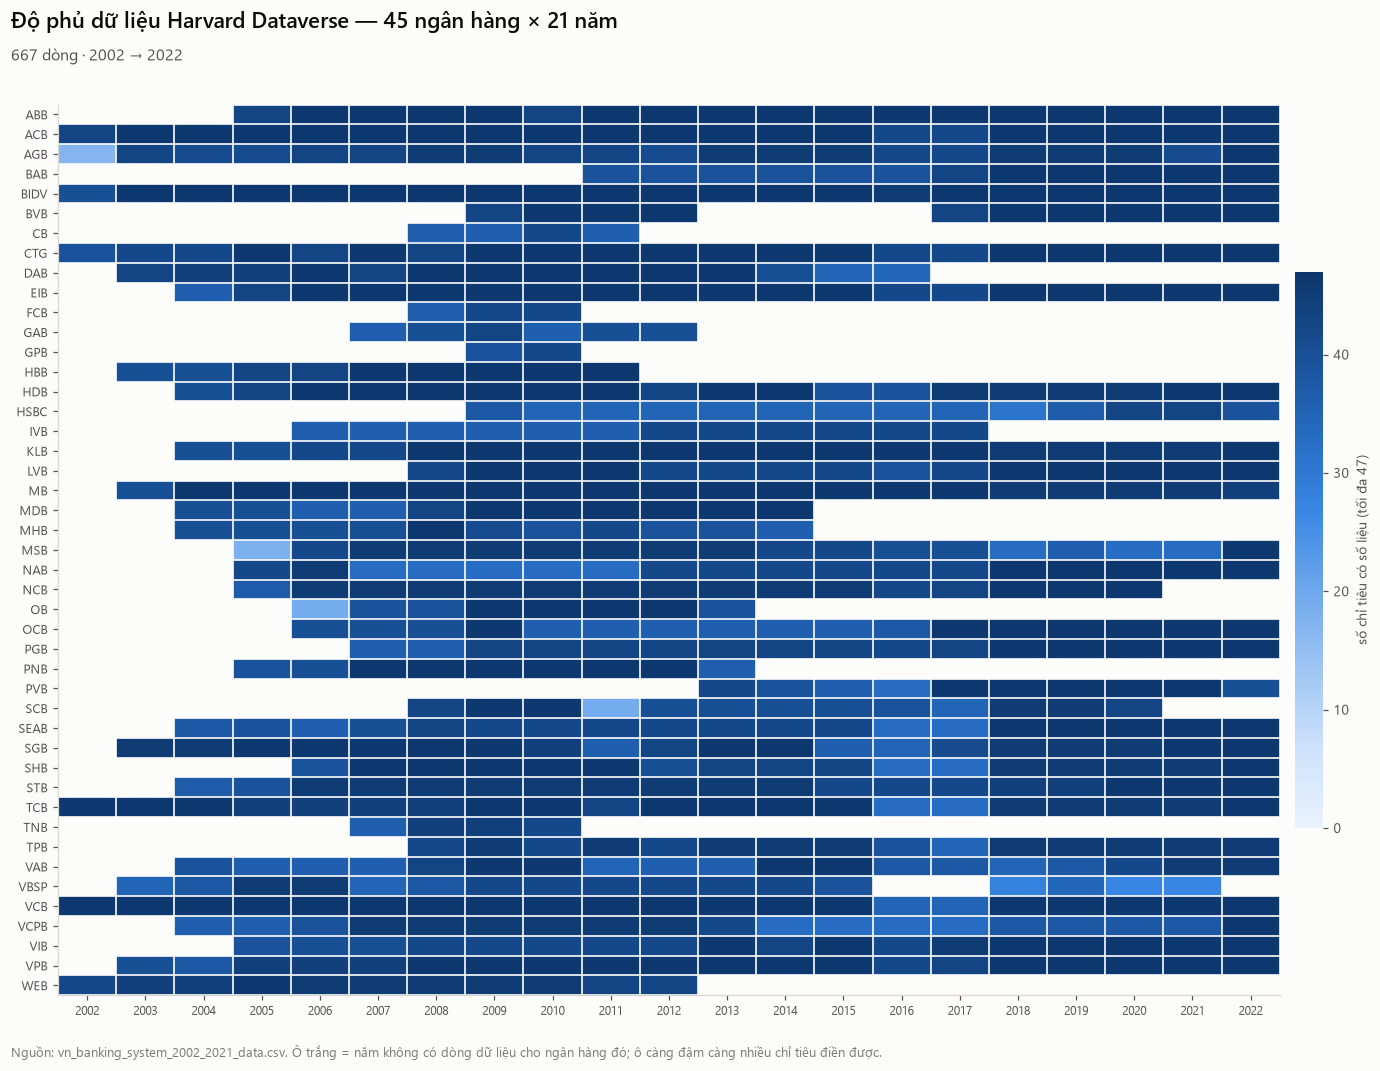

In [19]:
if CO_DV:
    dv = pd.read_csv(NGOAI / "vn_banking_system_2002_2021_data.csv", encoding="utf-8-sig",
                     low_memory=False)
    dv.columns = [c.strip() for c in dv.columns]
    dv["Year"] = pd.to_numeric(dv["Year"], errors="coerce").astype("Int64")
    so = dv.drop(columns=[c for c in ["Bank Code", "Year", "Classification"] if c in dv.columns])
    so = so.apply(pd.to_numeric, errors="coerce")
    dv["so_chi_tieu"] = so.notna().sum(axis=1)
    NH45 = sorted(dv["Bank Code"].dropna().unique())

    M_dv = (dv.pivot_table(index="Bank Code", columns="Year", values="so_chi_tieu", aggfunc="max")
            .reindex(NH45))
    fig, ax = plt.subplots(figsize=(12.6, 9.4))
    im = ban_do_nhiet(ax, M_dv, cmap=SEQ, chu=False, xoay=0, vmin=0, vmax=so.shape[1])
    cb = fig.colorbar(im, ax=ax, fraction=0.022, pad=0.012)
    cb.set_label(f"số chỉ tiêu có số liệu (tối đa {so.shape[1]})", fontsize=9, color=INK_2)
    cb.outline.set_visible(False)
    fig.tight_layout(rect=(0, 0, 1, dau_de(fig)))
    khung(fig, f"Độ phủ dữ liệu Harvard Dataverse — {len(NH45)} ngân hàng × "
                f"{M_dv.shape[1]} năm",
          f"{len(dv):,} dòng · {dv['Year'].min()} → {dv['Year'].max()}",
          "Nguồn: vn_banking_system_2002_2021_data.csv. Ô trắng = năm không có dòng dữ liệu cho "
          "ngân hàng đó; ô càng đậm càng nhiều chỉ tiêu điền được.")
    luu(fig, "doc_12a_do_phu_dataverse")
    plt.show()
else:
    print("Thiếu data/external/vn_banking_system_2002_2021_data.csv — bỏ qua mục 12.")

đã lưu → doc_12b_chi_nhanh_dataverse.png


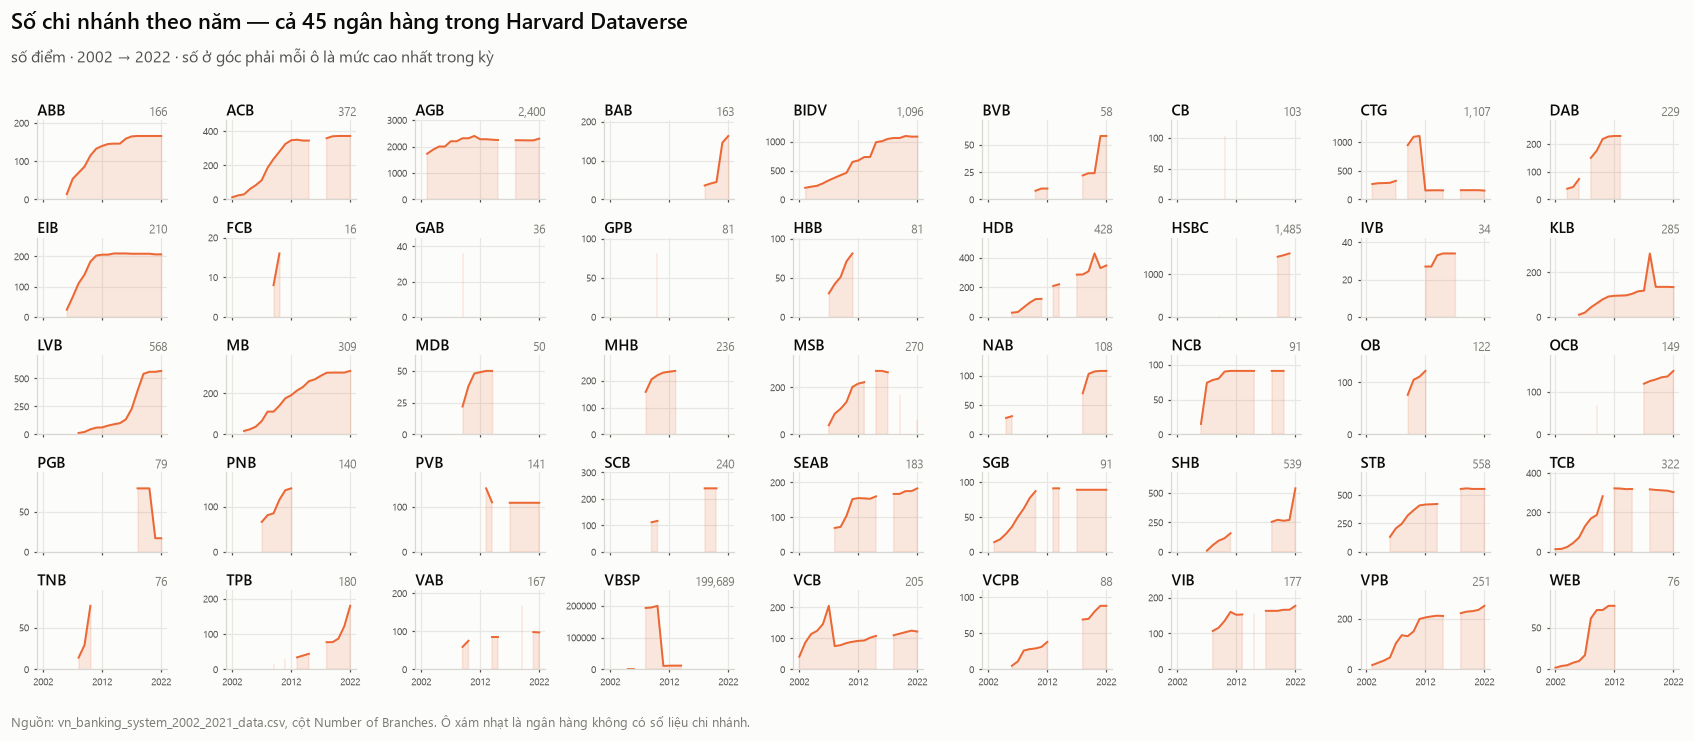

In [20]:
if CO_DV:
    cn = (dv.assign(cn=pd.to_numeric(dv["Number of Branches"], errors="coerce"))
          .pivot_table(index="Year", columns="Bank Code", values="cn", aggfunc="max").sort_index())

    fig, axes = luoi_nho(len(NH45), ncot=9, cao=1.28, rong=1.72, sharex=True)
    for ax, ma in zip(axes, NH45):
        v = cn[ma] if ma in cn.columns else pd.Series(dtype=float)
        if v.notna().any():
            ax.plot(v.index, v.to_numpy(dtype=float), lw=1.3, color=CAM)
            ax.fill_between(v.index, v.to_numpy(dtype=float), color=CAM, alpha=0.14)
            ax.set_ylim(0, np.nanmax(v.to_numpy(dtype=float)) * 1.25)
            ten_o(ax, ma, phu=f"{np.nanmax(v.to_numpy(dtype=float)):,.0f}")
        else:
            ten_o(ax, ma, mau=MUTED)
            ax.set_yticks([])
        ax.set_xticks([2002, 2012, 2022])
        ax.tick_params(labelsize=6.8)
    fig.tight_layout(rect=(0, 0, 1, dau_de(fig)))
    khung(fig, f"Số chi nhánh theo năm — cả {len(NH45)} ngân hàng trong Harvard Dataverse",
          "số điểm · 2002 → 2022 · số ở góc phải mỗi ô là mức cao nhất trong kỳ",
          "Nguồn: vn_banking_system_2002_2021_data.csv, cột Number of Branches. Ô xám nhạt là "
          "ngân hàng không có số liệu chi nhánh.")
    luu(fig, "doc_12b_chi_nhanh_dataverse")
    plt.show()

## 13. Mạng lưới điểm giao dịch — 22 ngân hàng

Ba góc nhìn của cùng một bộ điểm: tổng số theo loại điểm, phân bố theo tỉnh/thành, và vị trí thật
trên toạ độ địa lý.

đã lưu → doc_13a_mang_luoi_theo_nh.png


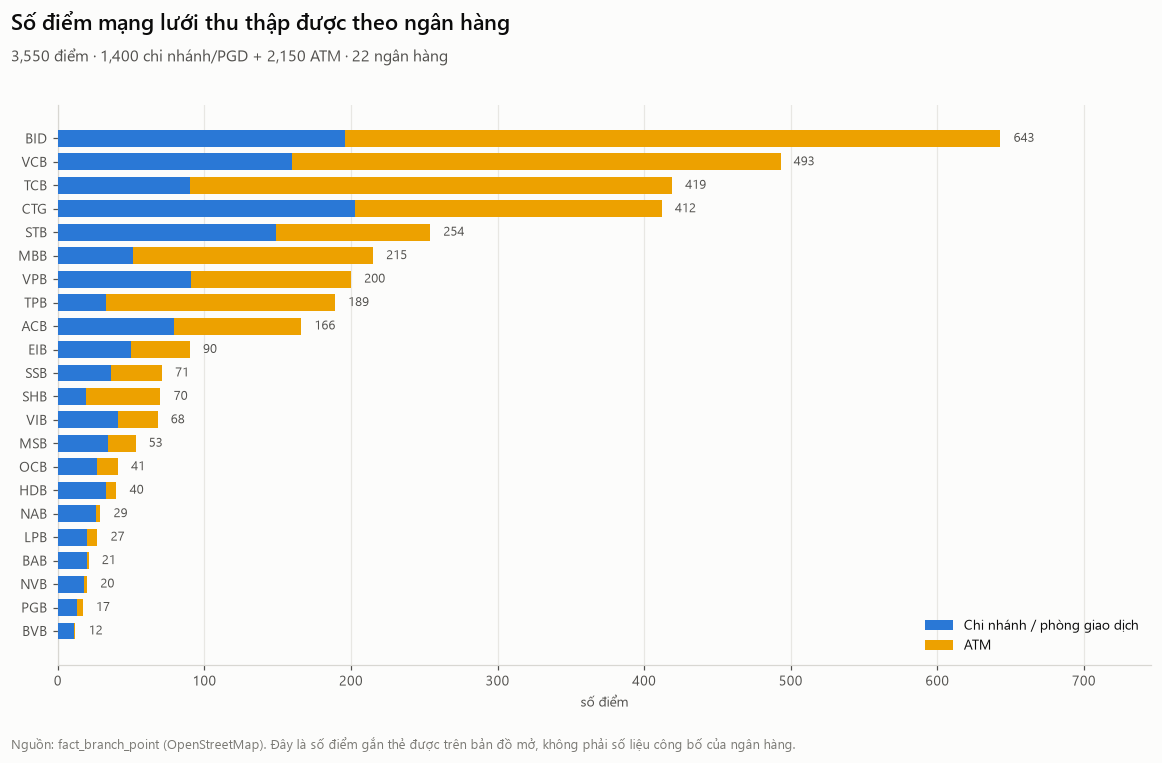

In [21]:
dm = diem_ml[diem_ml["ticker"].isin(NH22)]
dem = dm.pivot_table(index="ticker", columns="kind", values="osm_id", aggfunc="count").fillna(0)
dem = dem.reindex(NH22).fillna(0)
dem["tong"] = dem.sum(axis=1)
dem = dem.sort_values("tong", ascending=False)

fig, ax = plt.subplots(figsize=(10.6, 6.6))
y = np.arange(len(dem))
ax.barh(y, dem["bank"], height=0.72, color=XANH, label="Chi nhánh / phòng giao dịch", zorder=3)
ax.barh(y, dem["atm"], left=dem["bank"], height=0.72, color=VANG, label="ATM", zorder=3)
ax.set_yticks(y)
ax.set_yticklabels(dem.index, fontsize=9)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlim(0, dem["tong"].max() * 1.16)
for yi, (b, a, t) in enumerate(zip(dem["bank"], dem["atm"], dem["tong"])):
    ax.text(t + dem["tong"].max() * 0.014, yi, f"{t:,.0f}", va="center", fontsize=8.8, color=INK_2)
ax.legend(loc="lower right", fontsize=9)
ax.set_xlabel("số điểm", fontsize=9)

fig.tight_layout(rect=(0, 0, 1, dau_de(fig)))
khung(fig, "Số điểm mạng lưới thu thập được theo ngân hàng",
      f"{len(dm):,} điểm · {int(dem['bank'].sum()):,} chi nhánh/PGD + {int(dem['atm'].sum()):,} ATM · "
      f"{len(NH22)} ngân hàng",
      "Nguồn: fact_branch_point (OpenStreetMap). Đây là số điểm gắn thẻ được trên bản đồ mở, "
      "không phải số liệu công bố của ngân hàng.")
luu(fig, "doc_13a_mang_luoi_theo_nh")
plt.show()

đã lưu → doc_13b_mang_luoi_theo_tinh.png


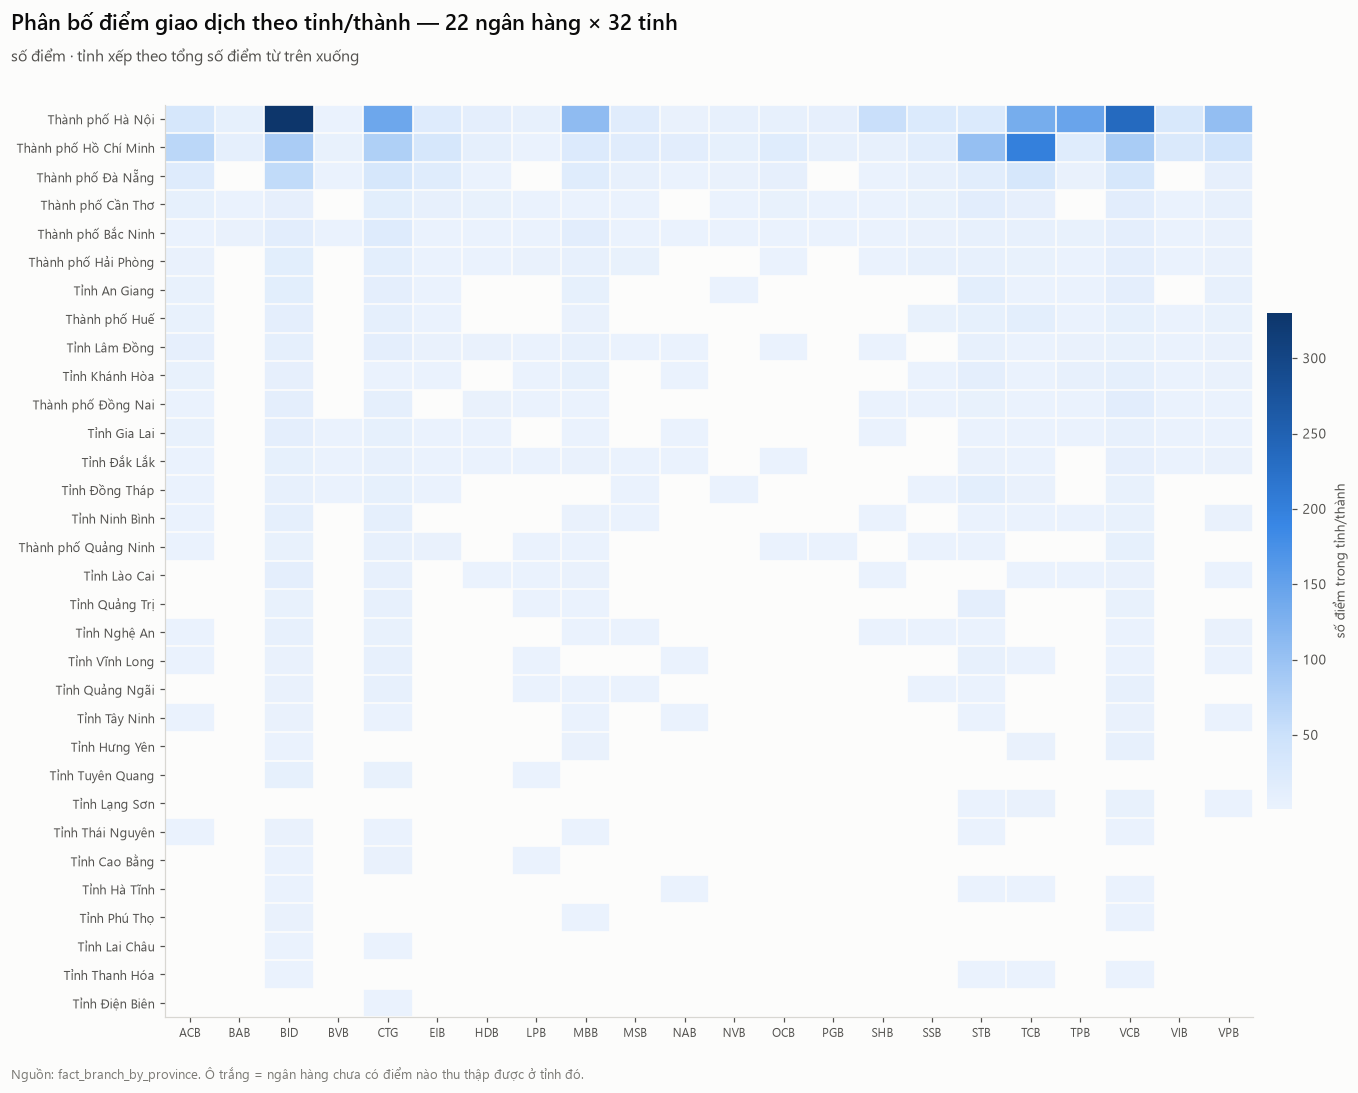

In [22]:
M_tinh = (tinh_ml[tinh_ml["ticker"].isin(NH22)]
          .pivot_table(index="province", columns="ticker", values="n_total", aggfunc="sum")
          .reindex(columns=NH22))
M_tinh = M_tinh.loc[M_tinh.sum(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(12.4, 9.6))
im = ban_do_nhiet(ax, M_tinh, cmap=SEQ, chu=False, xoay=0)
cb = fig.colorbar(im, ax=ax, fraction=0.022, pad=0.012)
cb.set_label("số điểm trong tỉnh/thành", fontsize=9, color=INK_2)
cb.outline.set_visible(False)
fig.tight_layout(rect=(0, 0, 1, dau_de(fig)))
khung(fig, f"Phân bố điểm giao dịch theo tỉnh/thành — {M_tinh.shape[1]} ngân hàng × "
            f"{M_tinh.shape[0]} tỉnh",
      "số điểm · tỉnh xếp theo tổng số điểm từ trên xuống",
      "Nguồn: fact_branch_by_province. Ô trắng = ngân hàng chưa có điểm nào thu thập được ở "
      "tỉnh đó.")
luu(fig, "doc_13b_mang_luoi_theo_tinh")
plt.show()

đã lưu → doc_13c_ban_do_diem.png


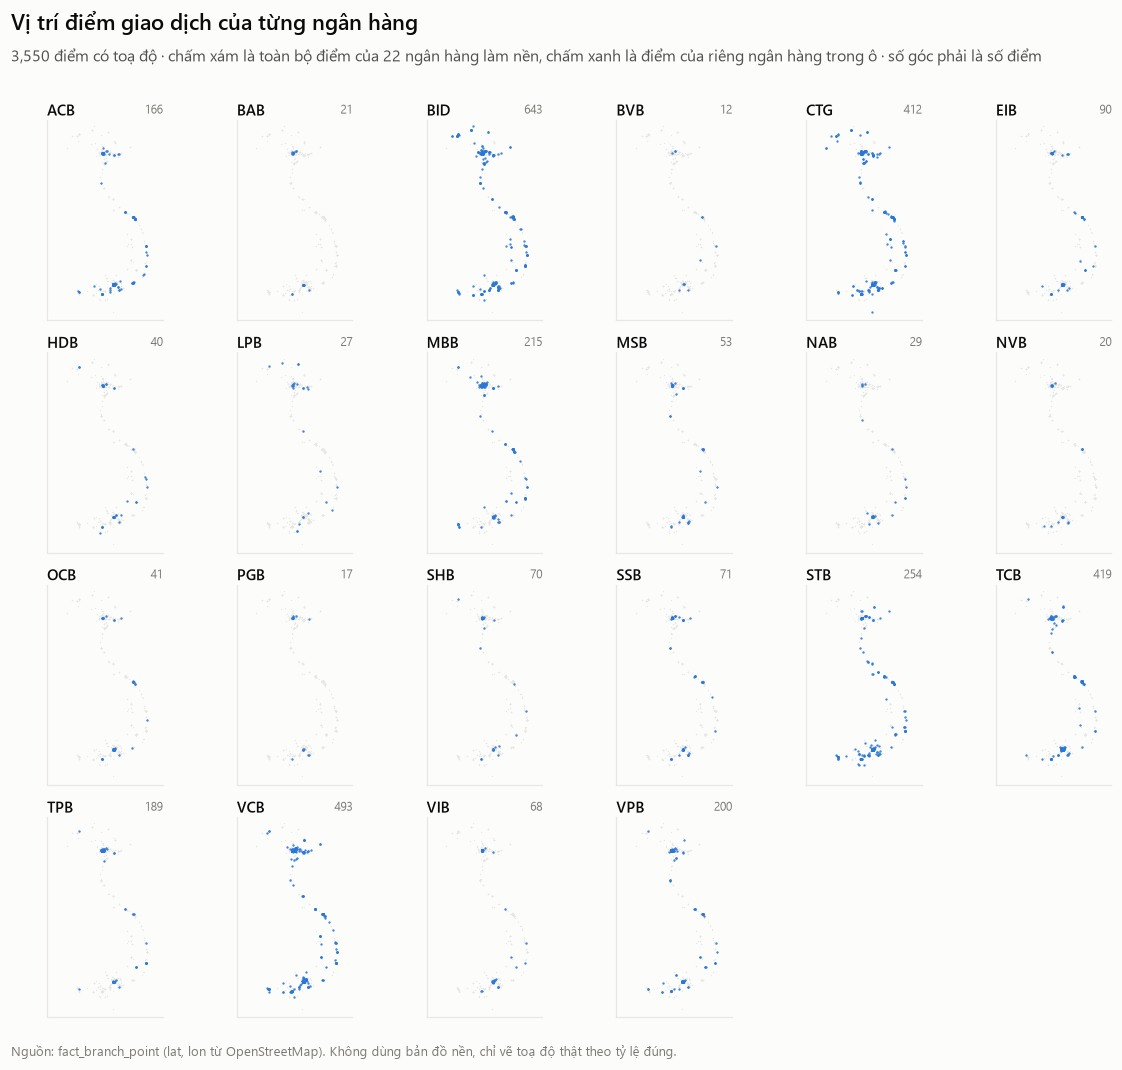

In [23]:
dm_xy = dm.dropna(subset=["lat", "lon"])
fig, axes = luoi_nho(22, ncot=6, cao=2.35, rong=1.75)
for ax, ma in zip(axes, NH22):
    d = dm_xy[dm_xy["ticker"] == ma]
    ax.scatter(dm_xy["lon"], dm_xy["lat"], s=0.7, color=GRID, lw=0, zorder=1)
    ax.scatter(d["lon"], d["lat"], s=2.4, color=XANH, lw=0, alpha=0.85, zorder=2)
    ten_o(ax, ma, phu=f"{len(d):,}")
    ax.set_xlim(101.5, 110.5)
    ax.set_ylim(8, 23.6)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    for s in ax.spines.values():
        s.set_color(GRID)
fig.tight_layout(rect=(0, 0, 1, dau_de(fig)))
khung(fig, "Vị trí điểm giao dịch của từng ngân hàng",
      f"{len(dm_xy):,} điểm có toạ độ · chấm xám là toàn bộ điểm của 22 ngân hàng làm nền, "
      "chấm xanh là điểm của riêng ngân hàng trong ô · số góc phải là số điểm",
      "Nguồn: fact_branch_point (lat, lon từ OpenStreetMap). Không dùng bản đồ nền, chỉ vẽ toạ độ "
      "thật theo tỷ lệ đúng.")
luu(fig, "doc_13c_ban_do_diem")
plt.show()

## 14. Đánh giá ứng dụng ngân hàng — 22 ngân hàng, 2012-01 → 2026-08

Số lượt đánh giá theo tháng của từng ứng dụng, rồi điểm trung bình và tổng lượt đánh giá hiện tại.

đã lưu → doc_14a_luot_danh_gia_theo_thang.png


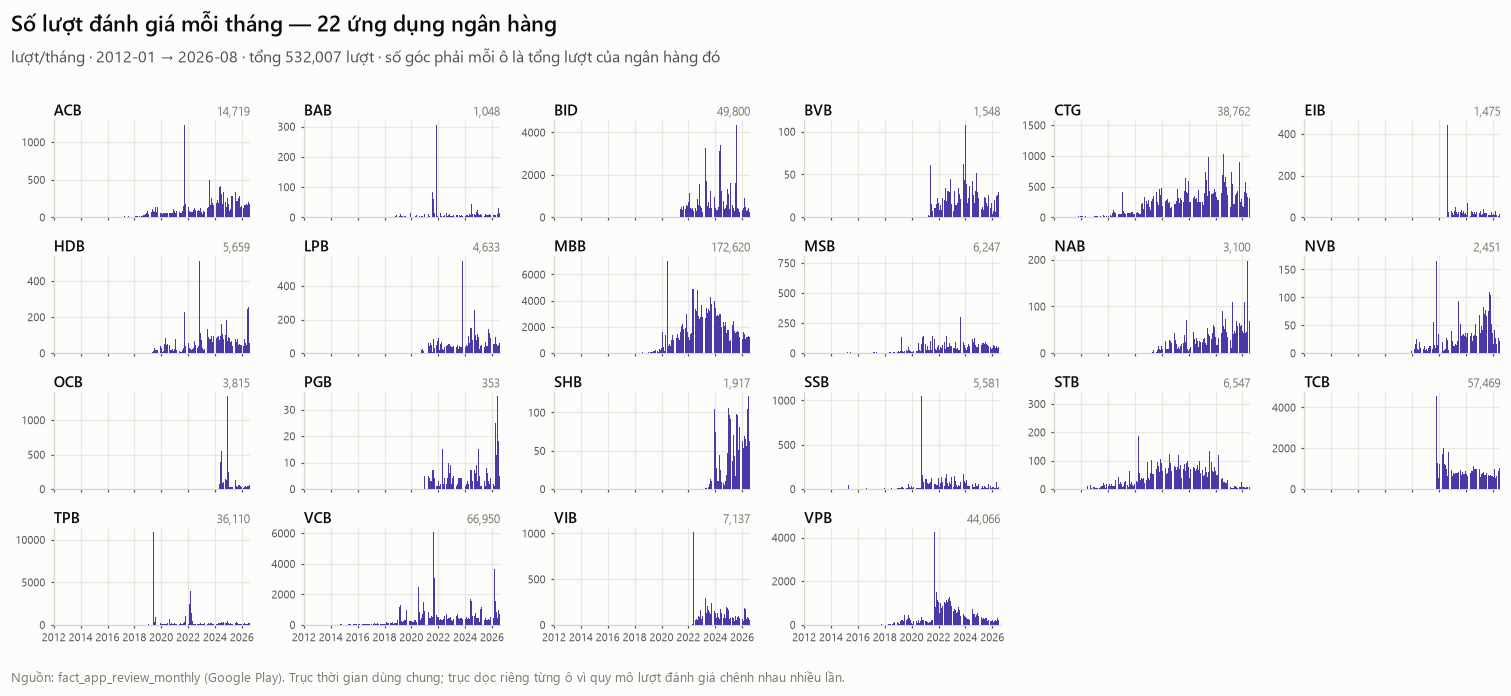

In [24]:
ap = app_thang[app_thang["ticker"].isin(NH22)].sort_values("month_date")

fig, axes = luoi_nho(22, ncot=6, cao=1.5, rong=2.3, sharex=True)
for ax, ma in zip(axes, NH22):
    d = ap[ap["ticker"] == ma]
    ax.bar(d["month_date"], d["n_reviews"], width=26, color=TIM, zorder=3)
    ten_o(ax, ma, phu=f"{d['n_reviews'].sum():,.0f}")
    ax.tick_params(axis="x", labelsize=7)
    ax.set_xlim(ap["month_date"].min(), ap["month_date"].max())
fig.tight_layout(rect=(0, 0, 1, dau_de(fig)))
khung(fig, "Số lượt đánh giá mỗi tháng — 22 ứng dụng ngân hàng",
      f"lượt/tháng · {ap['month'].min()} → {ap['month'].max()} · "
      f"tổng {ap['n_reviews'].sum():,.0f} lượt · số góc phải mỗi ô là tổng lượt của ngân hàng đó",
      "Nguồn: fact_app_review_monthly (Google Play). Trục thời gian dùng chung; trục dọc riêng "
      "từng ô vì quy mô lượt đánh giá chênh nhau nhiều lần.")
luu(fig, "doc_14a_luot_danh_gia_theo_thang")
plt.show()

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_14368\2666137624.py:20: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Segoe UI.
  fig.tight_layout(rect=(0, 0, 1, dau_de(fig)))
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_14368\371598215.py:40: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Segoe UI.
  fig.savefig(FIGDIR / (ten + ".png"))


đã lưu → doc_14b_diem_va_luot.png


d:\KLTN\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Segoe UI.
  fig.canvas.print_figure(bytes_io, **kw)


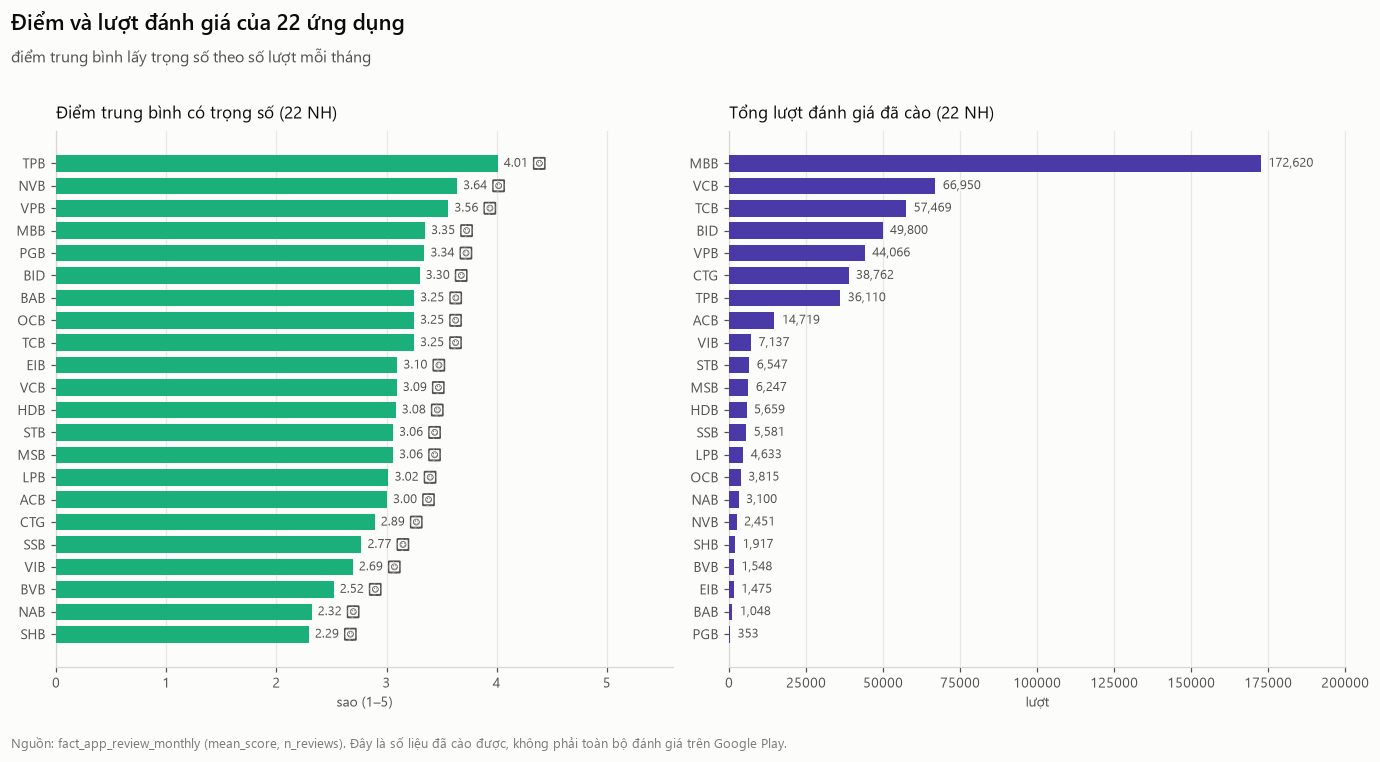

In [25]:
tong = (ap.groupby("ticker")
        .apply(lambda d: pd.Series({
            "luot": d["n_reviews"].sum(),
            "diem": np.average(d["mean_score"], weights=d["n_reviews"]) if d["n_reviews"].sum() else np.nan,
        }), include_groups=False)
        .reindex(NH22))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.6, 6.6))
d1 = tong["diem"].dropna().sort_values(ascending=False)
thanh_ngang(ax1, d1.index, d1.to_numpy(), mau=NGOC, dinh_dang="{:.2f}", don_vi=" ★")
ax1.set_xlim(0, 5.6)
ax1.set_title(f"Điểm trung bình có trọng số ({len(d1)} NH)", fontsize=11, loc="left", pad=8)
ax1.set_xlabel("sao (1–5)", fontsize=9)

d2 = tong["luot"].dropna().sort_values(ascending=False)
thanh_ngang(ax2, d2.index, d2.to_numpy(), mau=TIM, dinh_dang="{:,.0f}")
ax2.set_title(f"Tổng lượt đánh giá đã cào ({len(d2)} NH)", fontsize=11, loc="left", pad=8)
ax2.set_xlabel("lượt", fontsize=9)

fig.tight_layout(rect=(0, 0, 1, dau_de(fig)))
khung(fig, "Điểm và lượt đánh giá của 22 ứng dụng",
      "điểm trung bình lấy trọng số theo số lượt mỗi tháng",
      "Nguồn: fact_app_review_monthly (mean_score, n_reviews). Đây là số liệu đã cào được, không "
      "phải toàn bộ đánh giá trên Google Play.")
luu(fig, "doc_14b_diem_va_luot")
plt.show()

## Tổng kết — các hình đã xuất

Tất cả PNG 190 dpi nằm trong `figures_doc/`, tên `doc_NN_*.png` theo đúng thứ tự 14 mục của tài
liệu, chèn thẳng vào bản Word/LaTeX được.

In [26]:
ds = sorted(FIGDIR.glob("doc_*.png"))
print(f"{len(ds)} hình trong {FIGDIR}\n")
for p in ds:
    print(f"  {p.name:44s} {p.stat().st_size / 1024:6.0f} KB")

22 hình trong D:\KLTN\figures_doc

  doc_01a_gia_dong_cua_22nh.png                   332 KB
  doc_01b_do_phu_gia.png                          125 KB
  doc_02a_tong_tai_san_22nh.png                   238 KB
  doc_02b_do_day_chi_tieu.png                     246 KB
  doc_03a_du_no_22nh.png                          229 KB
  doc_03b_ldr_npl.png                             180 KB
  doc_04_chi_phi_von.png                          151 KB
  doc_05_loi_suat_tssl.png                        252 KB
  doc_06_cpi.png                                  128 KB
  doc_07_tang_truong_tin_dung.png                  68 KB
  doc_08_lai_suat_dieu_hanh.png                    80 KB
  doc_09_binh_quan_nganh.png                      286 KB
  doc_10_lai_suat_cho_vay.png                     254 KB
  doc_11a_lai_suat_tiet_kiem.png                  332 KB
  doc_11b_lai_suat_tiet_kiem_theo_ngay.png        132 KB
  doc_12a_do_phu_dataverse.png                    149 KB
  doc_12b_chi_nhanh_dataverse.png                 294